# CONVIVE · Final notebook

Team 102_A (Convive Lab) · Project Management GP2627, UPF · final delivery, November 2026 · WBS 3.3.2

**Question of the Project Charter.** How does the presence of regional, national and international visitors change over time in the neighbourhoods of Barcelona, compared with residents?

| Part | What it does | WBS |
|---|---|---|
| 1 | Preparation: reads the monthly Smart Steps files, checks and cleans them, builds the aggregated tables | 3.1.x, 2.2.1 |
| 2 | Validation of the aggregated tables | 2.2.2 |
| 3 | Answer to the Charter question | 5.2 |
| 4 | Answers to Q1-Q20, each with a decision rule fixed in advance | 3.2.x |
| 5 | Robustness of the verdicts and limits of the data | 5.3 |

**How to read it.** Trips, unique visitors and presences are three different measures and are never mixed. A count below 15 reads `<15` and never means "nobody". The results describe patterns, not causes. Outputs show aggregated values only (NDA).

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

import aggregates as A
import breaks as B
import coexistence as C
import final_outputs as F
import research as R
import research_report as RR
import sensitivity as S
import validation as V

pd.set_option("display.max_colwidth", 110, "display.width", 200, "display.max_rows", 80)
RAW = A.TOURISM_DIR.exists() and A.MOBILITY_DIR.exists()
print("Raw data on this computer:", RAW)

Raw data on this computer: True


## 1. Preparation

With the raw files this part runs the whole pipeline: CSV to Parquet, inventory, inspection, geographic and temporal levels, quality checks, cleaning, descriptive statistics and the aggregated tables. Every step writes its own report in `deliverables/`. Without the raw files the notebook uses the aggregated tables already built.

In [2]:
if RAW:
    import run_iteration2
    run_iteration2.main()
else:
    print("No raw data here: starting from the aggregated tables")

--- build


Done: 0 converted, 384 already up to date, 0s


--- build done in 0s


--- inventory


deliverables\iteration2\3.1.0_data_inventory.md
--- inventory done in 1s


--- inspect


... (93 outputs left out)

  overnight_stays_distribution.csv: 42 rows, 2 KB


deliverables\iteration2\3.1.6_summary.md
--- stats done in 6s


--- maps


Maps written
--- maps done in 3s


In [3]:
if RAW:
    A.run_tourism()
    A.run_mobility()
sorted(p.name for p in R.AGG.glob("*.csv")) + sorted(p.name for p in R.STATS.glob("*.csv"))

T6...


  t6_municipality_city_month.csv: 8,349 rows, 524 KB


  t6_municipality_barrio_year.csv: 43,864 rows, 3,636 KB


T7...


  t7_province_city_month.csv: 3,346 rows, 184 KB


  t7_province_barrio_year.csv: 10,633 rows, 816 KB


... (13 outputs left out)

  m1_outgoing_month_by_origin.csv: 9,344 rows, 400 KB


  m1_incoming_weekday_by_group.csv: 3,066 rows, 120 KB


M1 combined


['coverage_barrio_dataset.csv',
 'm1_incoming_weekday_by_group.csv',
 'm1_name_check.csv',
 'm1_od_year_by_origin.csv',
 'm1_outgoing_month_by_origin.csv',
 't5_barrio_daily_by_origin.csv',
 't6_municipality_barrio_year.csv',
 't6_municipality_city_month.csv',
 't7_province_barrio_year.csv',
 't7_province_city_month.csv',
 't8_country_barrio_year.csv',
 't8_country_city_month.csv',
 't9_profile_barrio_year.csv',
 't9_profile_city_month.csv',
 'barrio_concentration.csv',
 'barrio_incoming_trips_by_origen.csv',
 'barrio_monthly_by_origin_type.csv',
 'barrio_yoy_jan_aug.csv',
 'city_daily_by_origin.csv',
 'city_monthly_by_origin_type.csv',
 'city_weekday_by_origin.csv',
 'city_yoy_jan_aug.csv',
 'overnight_stays_distribution.csv']

## 2. Validation

Seventeen checks. The strongest one compares the trip totals through two separate paths (raw CSV with pandas, clean Parquet with DuckDB).

In [4]:
failed = V.main()
assert not failed, "A blocking validation check failed"
pd.read_csv(V.OUT_CSV)[["#", "area", "check", "result"]]

Validation: 16/17 passed, 0 failed
 #                                                                                                                       check result                                                                          evidence
 1                                                      No exported count of people or trips between 1 and 14 (written as <15)   PASS                                                   23 tables scanned; 0 violations
 2 M1 trips per year and origin are identical through two independent paths (raw CSV with pandas vs clean Parquet with DuckDB)   PASS                12 year x origin totals, 1,920,012,572 trips; largest difference 0
 3                                                         Share of published zero flows (<15 trips) is the same in both paths   PASS 42.4802% vs 42.4802%. Zeros stay 0 with a flag; they are never read as 'no trips'
 4                              T4: the largest neighbourhood never exceeds the city value of T1 (sam

,#,area,check,result
0,1,Privacy,No exported count of people or trips between 1 and 14 (written as <15),PASS
1,2,Totals,M1 trips per year and origin are identical through two independent paths (raw CSV with pandas vs clean Par...,PASS
2,3,Zeros,Share of published zero flows (<15 trips) is the same in both paths,PASS
3,4,Not additive,"T4: the largest neighbourhood never exceeds the city value of T1 (same month, origin and type)",PASS
4,5,Not additive,"T4: summing neighbourhoods gives MORE than the city people (so sums are labelled presences, never people)",PASS
5,6,Not additive,"T8: country presences >= T1 international people, and the largest single neighbourhood-country cell <= T1",PASS
6,7,Not additive,T5: the largest neighbourhood of each day never exceeds the city value of T2,PASS
7,8,Coverage,T6: 32 months present (Jan 2023 to Aug 2025),PASS
8,9,Coverage,T7: 32 months present (Jan 2023 to Aug 2025),PASS
9,10,Coverage,T8: 32 months present (Jan 2023 to Aug 2025),PASS


## 3. The Charter question

Residents exist only in the mobility product, so visitors and residents are compared with trips between neighbourhoods (M1).

In [5]:
t, r = R.run_all()
RR.make_figures(t, r)
RR.write_all(t, r)
F.main()
q0 = C.run(t)
display(Markdown(f"**{q0['question']}**\n\n*Rule.* {q0['decision_rule']}\n\n{q0['answer']}\n\n**Verdict: {q0['verdict']}. "
                 f"Belief holds: {q0['belief_holds']}.**\n\n*Limitation.* {q0['limitation']}"))

  figure: fig_q1


  figure: fig_q2


  figure: fig_q3


  figure: fig_q4


  figure: fig_q5


  figure: fig_q6


... (13 outputs left out)

  figure: fig_nat_regions


  3.2.4_quantified_answers.md
  3.2.1_exploratory_analysis.md
  3.2.2_geographic_analysis.md
  3.2.3_temporal_analysis.md
  3.2.0_ResearchQuestions_v0.3.md


   5.2_charter_answer.csv
   5.2_charter_month.csv
   5.2_charter_origins.csv
   5.2_charter_question.csv
   5.2_key_findings.csv
   5.2_key_findings.md
   5.3_level_shifts.csv
   5.3_limitations.md
   5.3_verdict_robustness.csv
   5.3_zone_transfer.csv
   figures\charter_barrios.png
   figures\charter_maps.png
   figures\charter_time.png
   figures\level_shifts.png
   figures\verdict_robustness.png


**Did the visitor share of incoming trips rise by at least 2 points in at least half of the 73 neighbourhoods between 2023 and 2025?**

*Rule.* Visitors GAIN GROUND in a neighbourhood if their share of incoming trips (M1, January-August) rises by at least 2 percentage points between 2023 and 2025, LOSE GROUND if it falls by at least 2 points, and are STABLE in between. The belief holds if they gain ground in at least 37 of 73 neighbourhoods (half); PARTLY if 19 to 36; NO if fewer.

Visitors made 43.8% of the trips between neighbourhoods in January-August 2023, 45.1% in 2024 and 45.9% in 2025. Trips per day changed by +11.5% for visitors and +2.4% for residents between 2023 and 2025 (international +26.2%, national -11.6%, regional +4.1%). Visitors gain ground in 39 of 73 neighbourhoods, are stable in 25 and lose ground in 9. In 2025 visitors dominate (above 60%) in 3 neighbourhoods, visitors and residents share 23 (40-60%) and residents dominate 47.

**Verdict: Visitors gain ground in 39 of 73 neighbourhoods and lose it in 9. Belief holds: Yes.**

*Limitation.* Trips, not people; trips inside a neighbourhood are excluded; a published 0 means fewer than 15 trips, so each share has bounds; two intervals cannot prove a long-term trend; no cause can be inferred.

In [6]:
q0["origins"].drop(columns="origen").round(3)

,origin,per_day_2023,share_2023,per_day_2024,share_2024,per_day_2025,share_2025,change_23_24,change_24_25,change_23_25
0,International,355946.626,0.188,411663.942,0.211,449090.419,0.223,0.157,0.091,0.262
1,National,109748.757,0.058,102376.029,0.052,97057.166,0.048,-0.067,-0.052,-0.116
2,Regional,363790.556,0.192,366882.860,0.188,378759.929,0.188,0.009,0.032,0.041
3,Resident,1062332.642,0.562,1070413.741,0.549,1088245.568,0.541,0.008,0.017,0.024


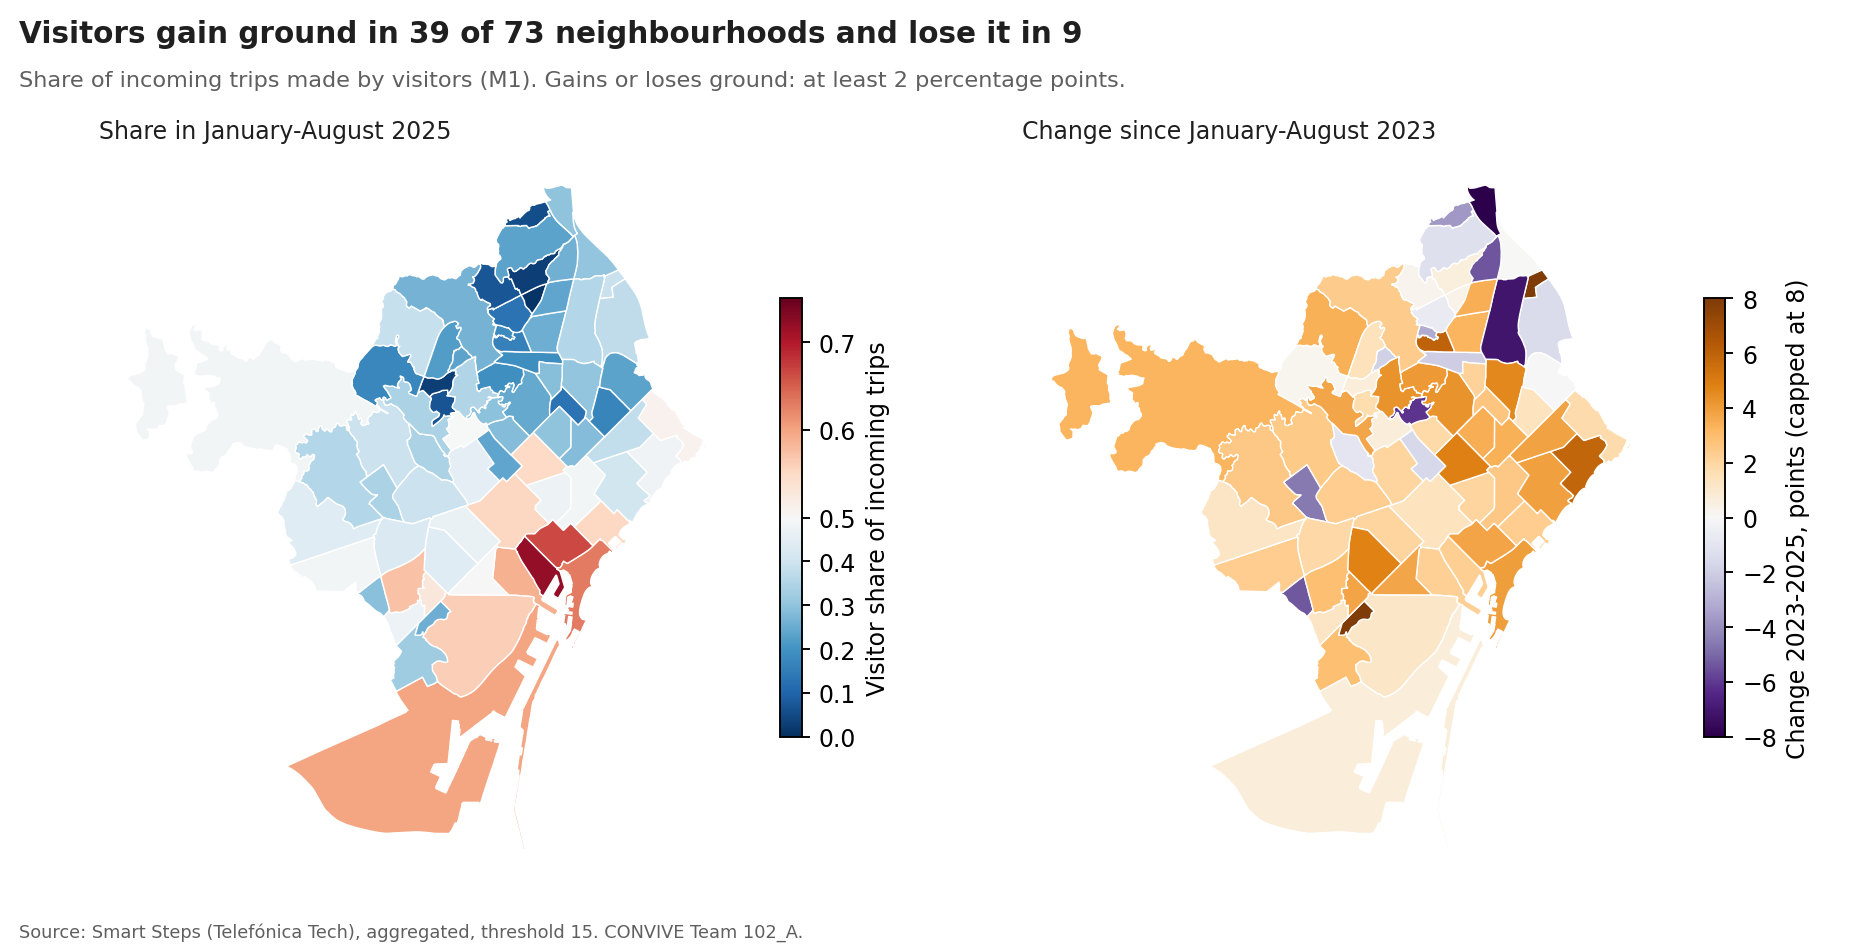

In [7]:
Image(filename=str(R.HERE / "deliverables" / "final/figures/charter_maps.png"))

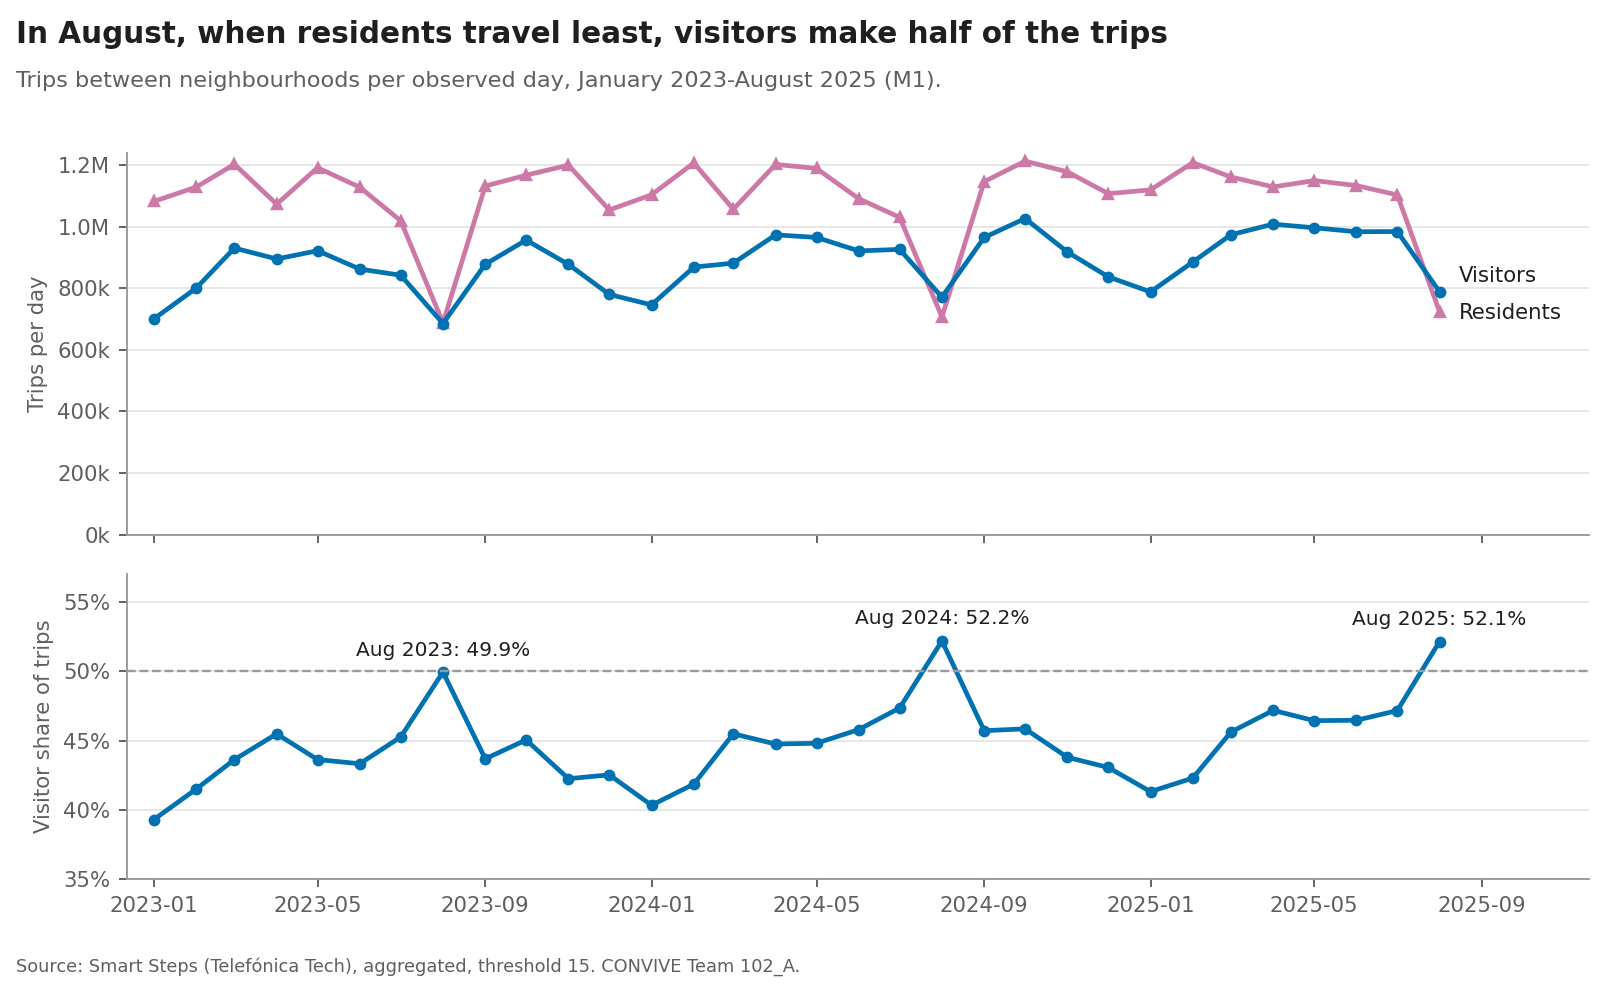

In [8]:
Image(filename=str(R.HERE / "deliverables" / "final/figures/charter_time.png"))

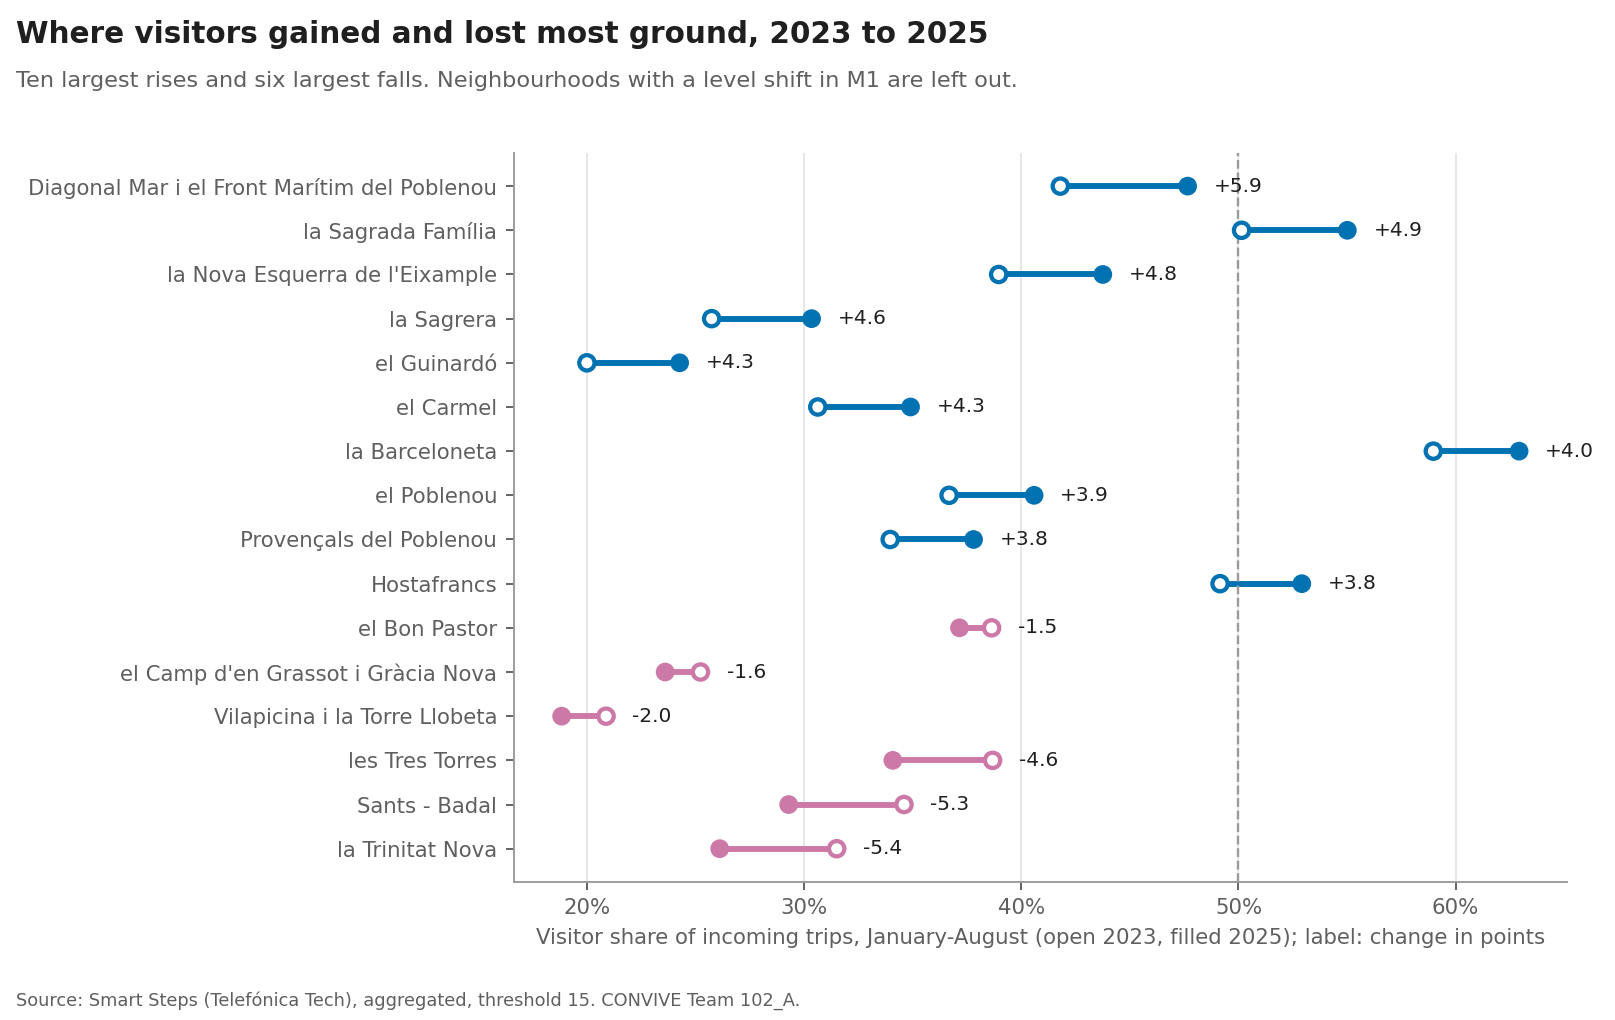

In [9]:
Image(filename=str(R.HERE / "deliverables" / "final/figures/charter_barrios.png"))

## 4. Twenty questions, twenty rules

`R.THRESHOLDS` holds the rules. They were written before the answers were computed, so the rule decides the verdict and not the number.

In [10]:
answers = RR.answers_table(r)


def show(qid):
    row = answers.set_index("id").loc[qid]
    display(Markdown(f"#### {qid} · {row.question}\n\n*Belief:* “{row.belief}”  \n*Rule:* {row.decision_rule}\n\n{row.answer}\n\n"
                     f"**Verdict: {row.verdict}. Belief holds: {row.belief_holds}.**  \n*Limitation:* {row.limitation}"))


answers[["id", "belief", "verdict", "belief_holds"]]

,id,belief,verdict,belief_holds
0,Q1,Tourists are everywhere in Barcelona.,Concentrated for all visitors; concentrated for international tourists,Yes
1,Q2,Tourism is only a summer problem.,Moderate seasonality overall; moderate seasonality for international tourists,No
2,Q3,Most visitors are foreign tourists.,"Partly: international majority in 22 of 32 months, the rule needs 24; the top 5 countries hold half of int...",Partly
3,Q4,Visitors flood the city at weekends.,Fewer at weekends (<= -5%),No
4,Q5,Tourism keeps growing every year.,Keeps growing overall (+2% rule); keeps growing for international tourists; keeps falling for national vis...,Yes
5,Q6,"In tourist neighbourhoods, visitors' movement outnumbers residents'.",True in 9 of 10 tourist neighbourhoods; false city-wide,Partly
6,Q7,Tourists only stay for a weekend.,Holds: most tourists stay 1-2 nights per week,Yes
7,Q8,The tourist neighbourhoods are the same all year round.,Stable ranking all year,Yes
8,Q9,Big events and holidays create visible peaks.,7 peak days and 25 low days found,Partly
9,Q10,Regional day-trippers go to the same places as foreign tourists.,Different places: regional day-trippers do not follow foreign tourists,No


### Where

In [11]:
show("Q1")

#### Q1 · How concentrated are visitors across the 73 neighbourhoods?

*Belief:* “Tourists are everywhere in Barcelona.”  
*Rule:* Visitors are CONCENTRATED if 50% of visitor presences fall in at most 11 neighbourhoods (15% of 73), i.e. N50 <= 11. SPREAD if N50 >= 22 (30% of 73). In between: MODERATELY concentrated.

Half of all visitor presences fall in 10 of 73 neighbourhoods (14%); N50 ranges 9-12 across the 32 months. The 10 largest hold 50.1% (Gini 0.59). International overnight tourists are more concentrated: N50 = 8 (60.5% in the top 10: la Dreta de l'Eixample, el Barri Gòtic, la Sagrada Família). Regional visitors are the most spread (N50 = 15).

**Verdict: Concentrated for all visitors; concentrated for international tourists. Belief holds: Yes.**  
*Limitation:* Neighbourhood values are not additive: shares are of presences (person x neighbourhood), not of people.

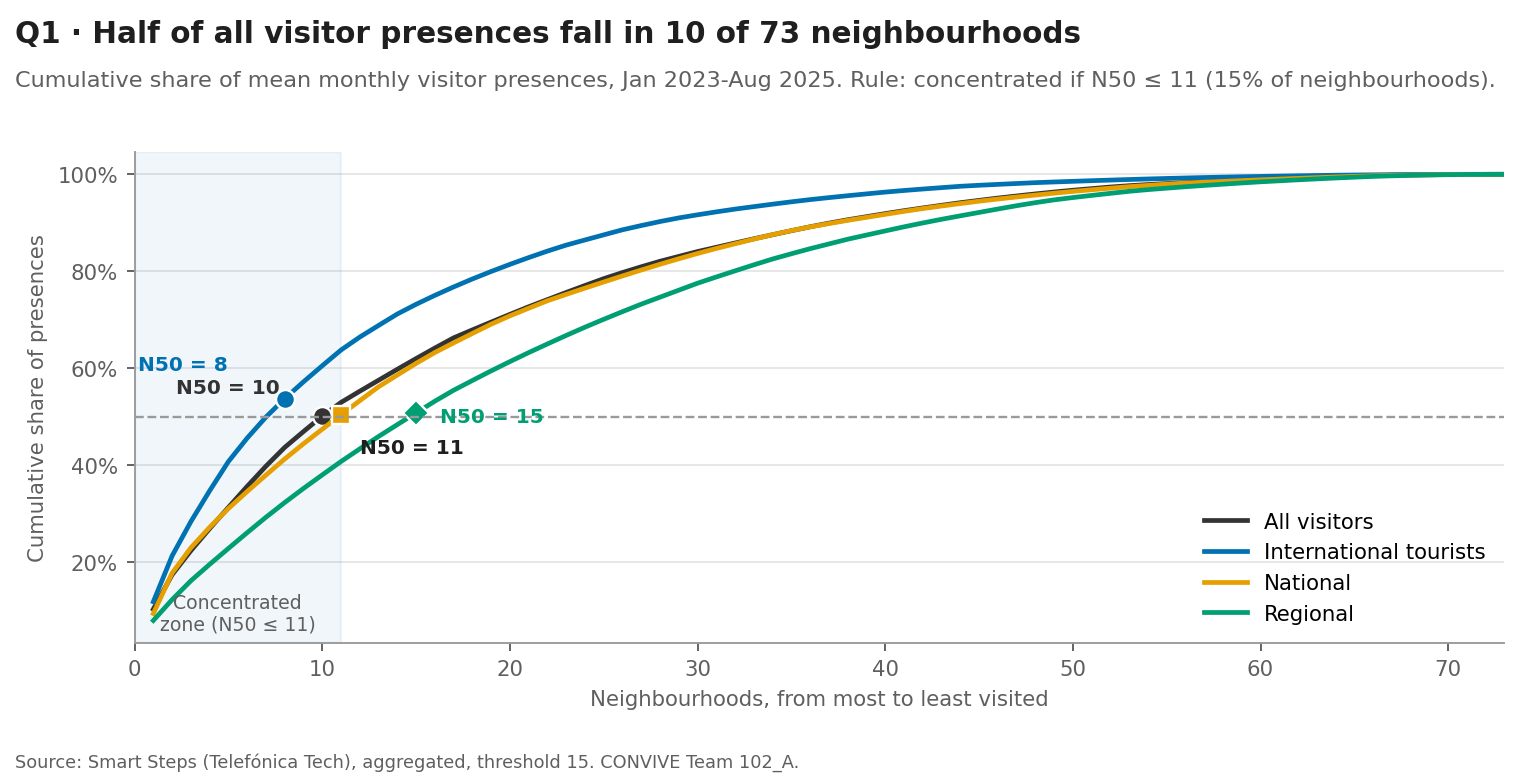

In [12]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q1_concentration.png"))

In [13]:
show("Q6")

#### Q6 · In the 10 most-visited neighbourhoods, do visitors make more than 50% of incoming trips?

*Belief:* “In tourist neighbourhoods, visitors' movement outnumbers residents'.”  
*Rule:* Tourist neighbourhoods = the 10 neighbourhoods with most mean monthly visitors (T4). In a neighbourhood visitors' trips OUTNUMBER residents' if the visitor share of incoming trips (M1) is above 50%, and ROBUSTLY so if even the low bound (published zeros counted as 14 resident trips) is above 50%.

In 9 of the 10 tourist neighbourhoods visitors make more than half of incoming trips (9 robustly): el Barri Gòtic 70.5%, Sant Pere, Santa Caterina i la Ribera 64.6%, la Barceloneta 60.5%, la Marina del Prat Vermell 60.0%, el Raval 57.8%, Sants 55.6%, el Poble-sec 55.5%, la Dreta de l'Eixample 54.7%, la Sagrada Família 53.0%. The others stay below 50% (lowest: l'Antiga Esquerra de l'Eixample 45.6%). City-wide, visitors make 44.7% of trips between neighbourhoods; 11 of 73 neighbourhoods are above 50%.

**Verdict: True in 9 of 10 tourist neighbourhoods; false city-wide. Belief holds: Partly.**  
*Limitation:* Trips, not people. Trips inside a neighbourhood are excluded.

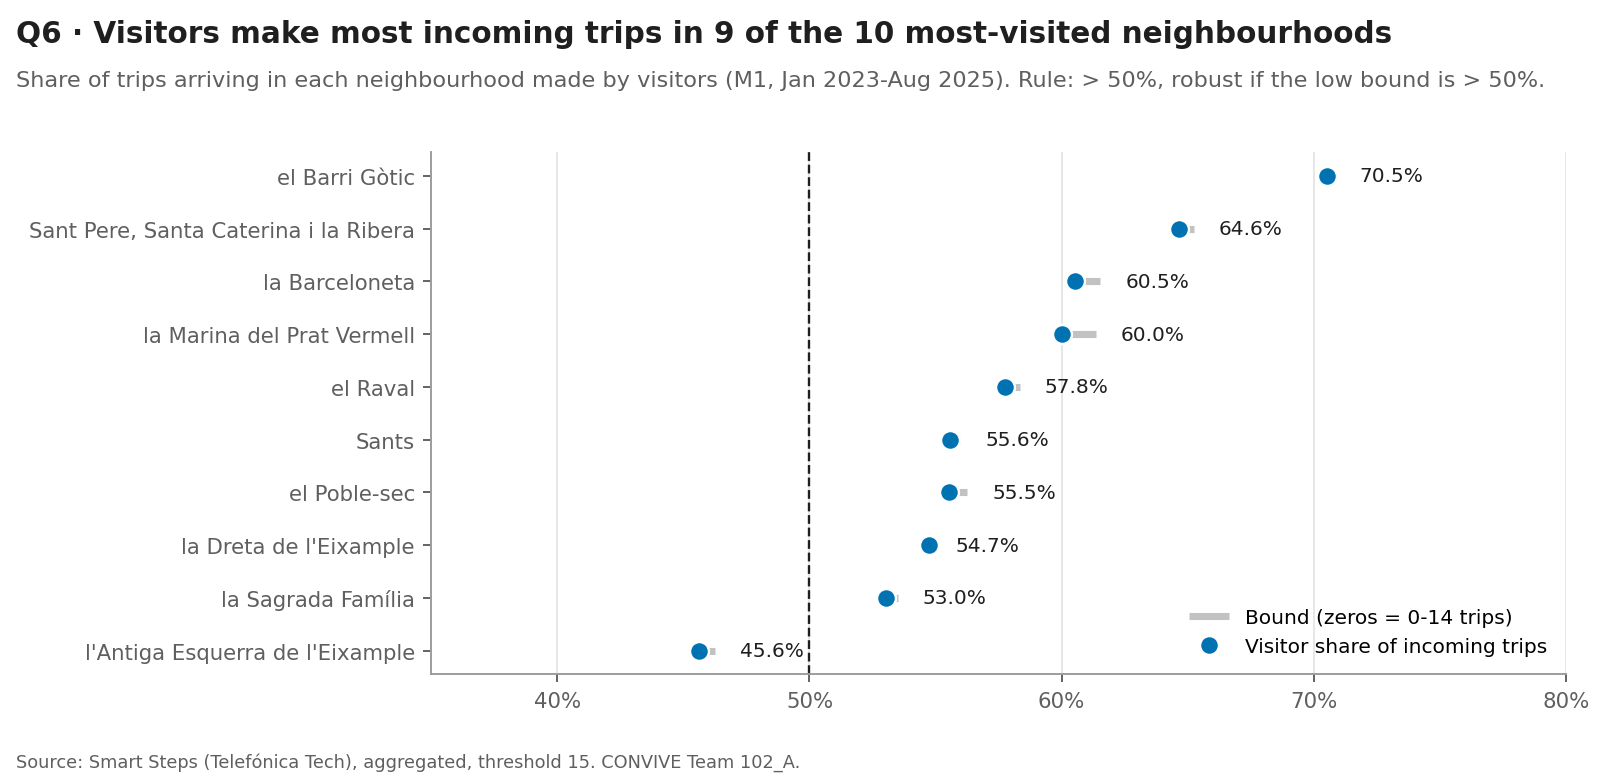

In [14]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q6_tourist_barris.png"))

In [15]:
show("Q8")

#### Q8 · Does the top 10 change between the peak and the lowest month?

*Belief:* “The tourist neighbourhoods are the same all year round.”  
*Rule:* The ranking is STABLE across seasons if at least 8 of the top 10 neighbourhoods of the peak month are also in the top 10 of the lowest month, and the Spearman rank correlation is at least 0.90.

2024: 9 of the top 10 in Jul (peak) are also top 10 in Jan (low); Spearman 0.986. Largest rank moves: Can Peguera (57->69), Sant Andreu (17->26), la Vall d'Hebron (58->50).

**Verdict: Stable ranking all year. Belief holds: Yes.**  
*Limitation:* Monthly values only.

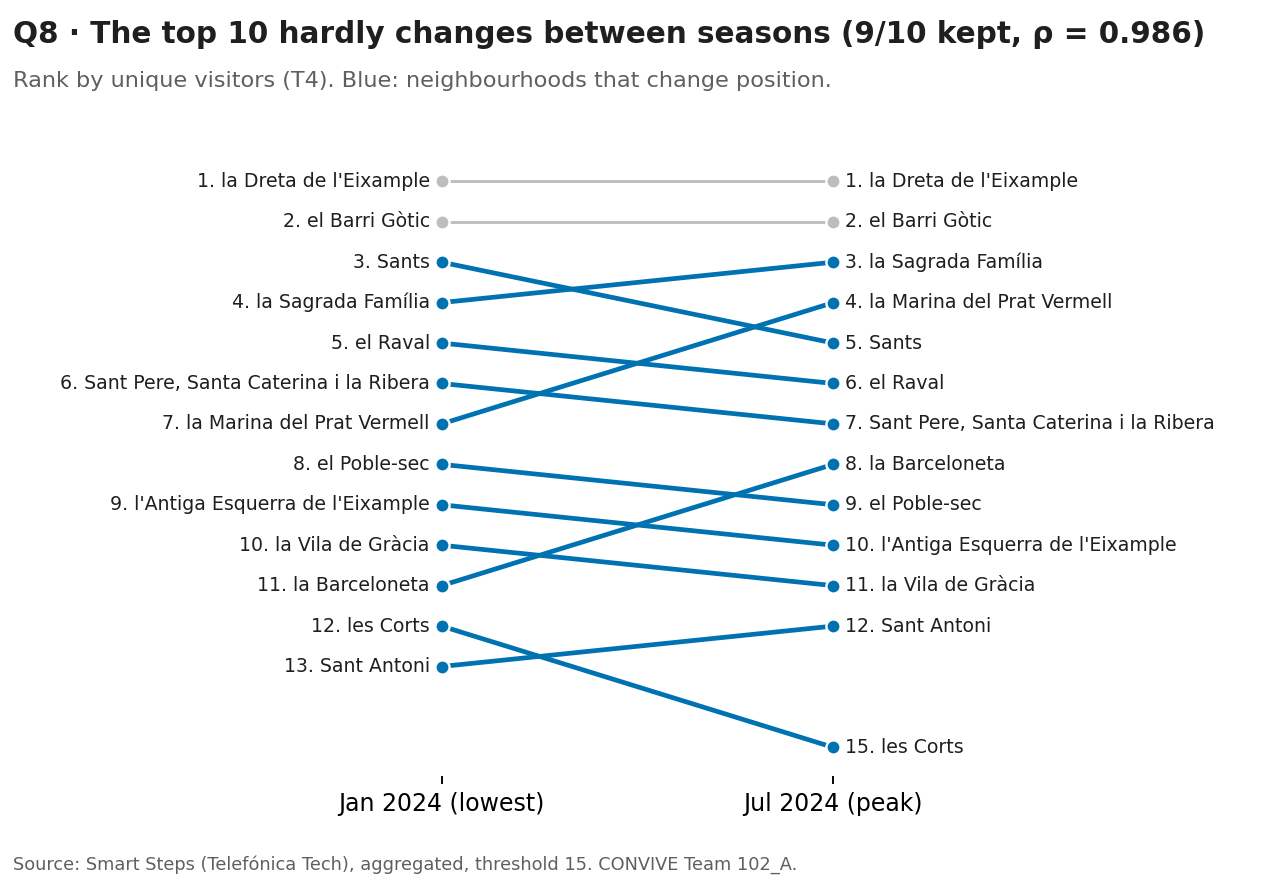

In [16]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q8_rank_season.png"))

In [17]:
show("Q10")

#### Q10 · Do the top-10 neighbourhoods of each origin coincide (7 of 10)?

*Belief:* “Regional day-trippers go to the same places as foreign tourists.”  
*Rule:* Origins go to the SAME PLACES if at least 7 of the top 10 neighbourhoods by mean monthly visitors coincide between two origins. A neighbourhood is SPECIALISED in an origin if LQ >= 1.25.

Overlap of the top-10 neighbourhoods: international-national 8/10, international-regional 5/10, national-regional 7/10. Neighbourhoods specialised (LQ >= 1.25): international 10, national 13, regional 45. Highest international LQ: la Salut (1.63); highest regional LQ: Ciutat Meridiana (2.50).

**Verdict: Different places: regional day-trippers do not follow foreign tourists. Belief holds: No.**  
*Limitation:* LQ uses presences, not people.

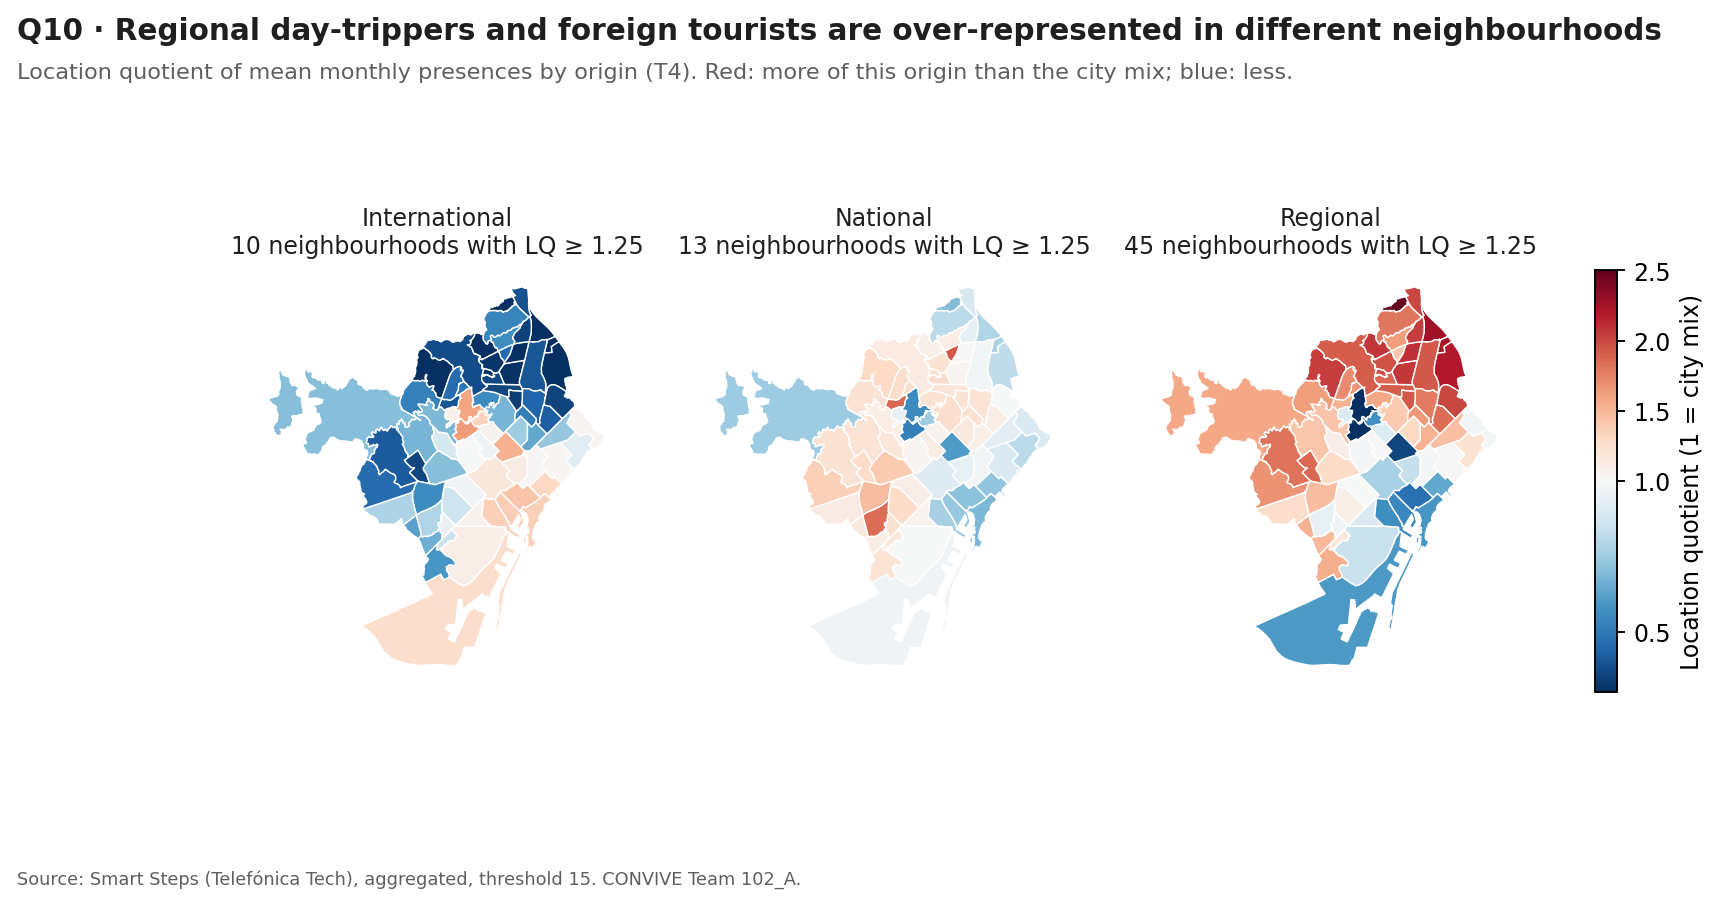

In [18]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q10_lq_maps.png"))

In [19]:
show("Q16")

#### Q16 · Is N50 of international tourists at least 2 neighbourhoods lower than for international excursionists?

*Belief:* “Overnight tourists crowd the same few places more than day-trippers.”  
*Rule:* Overnight tourists are MORE CONCENTRATED than excursionists if their N50 (see Q1) is at least 2 neighbourhoods lower.

N50 is 8 neighbourhoods for international tourists and 6 for international excursionists (gap -2); top-10 share 60.5% vs 66.4%.

**Verdict: No: international excursionists are even more concentrated. Belief holds: No.**  
*Limitation:* Same as Q1.

### When

In [20]:
show("Q2")

#### Q2 · How much higher are June-August than the rest of the year, by origin?

*Belief:* “Tourism is only a summer problem.”  
*Rule:* SUMMER-ONLY pattern if the June-August mean is at least 30% above the mean of the other nine months (ratio >= 1.30) in both full years. MODERATE seasonality if 1.10 to 1.30. NO marked seasonality if < 1.10. A month counts as a HIGH month if it is at least 90% of that year's peak.

June-August is 1.13x (2023) and 1.14x (2024) the other months for all visitors; 7 months of 2024 reach 90% of the peak (Apr, May, Jun, Jul, Aug, Sep, Oct), 4 of them outside summer. International tourists are the most seasonal (1.23x and 1.25x; peak-to-trough 1.71 in 2024).

**Verdict: Moderate seasonality overall; moderate seasonality for international tourists. Belief holds: No.**  
*Limitation:* 2025 covers January-August only and has no full-year ratio.

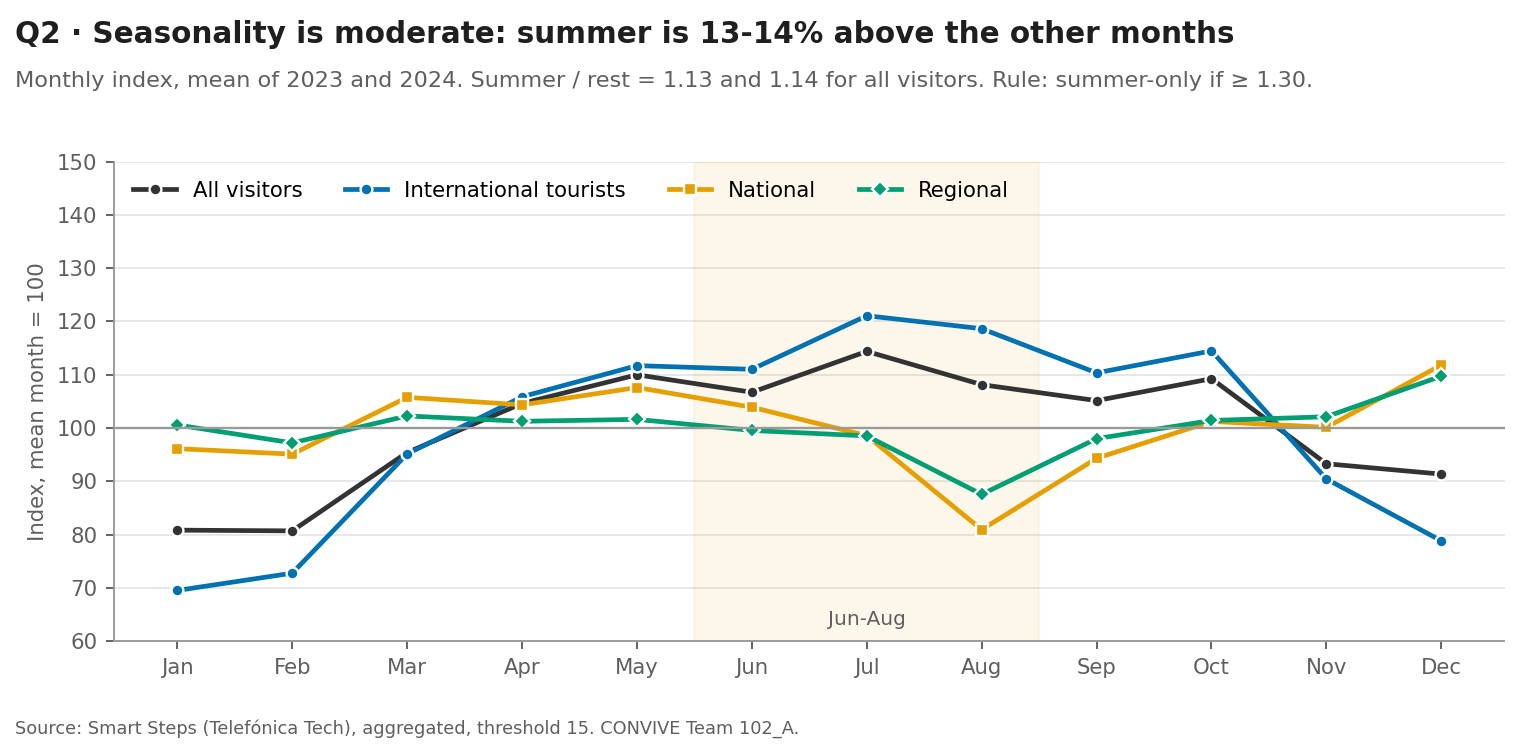

In [21]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q2_seasonality.png"))

In [22]:
show("Q4")

#### Q4 · Are mean daily visitors on Saturday-Sunday at least 10% above Monday-Friday?

*Belief:* “Visitors flood the city at weekends.”  
*Rule:* Visitors FLOOD the city at weekends if the mean daily unique visitors on Saturday and Sunday is at least 10% above Monday to Friday (ratio >= 1.10). NO DIFFERENCE if within +/-5%. FEWER at weekends if <= -5%. The same rule is applied to each neighbourhood (T5).

City (T2): 497,841 visitors per weekend day vs 539,023 per weekday, -7.6% (95% bootstrap interval -9.0% to -6.3%). International +0.3%, national -14.4%, regional -13.0%. Neighbourhoods (T5): 7 of 73 meet the weekend-flood rule (el Poble-sec, la Barceloneta, la Vila Olímpica del Poblenou, Sant Pere, Santa Caterina i la Ribera, Can Baró); 48 have fewer visitors at weekends.

**Verdict: Fewer at weekends (<= -5%). Belief holds: No.**  
*Limitation:* Daily values are never summed into weeks; 3 days are missing; T5 uses published values only.

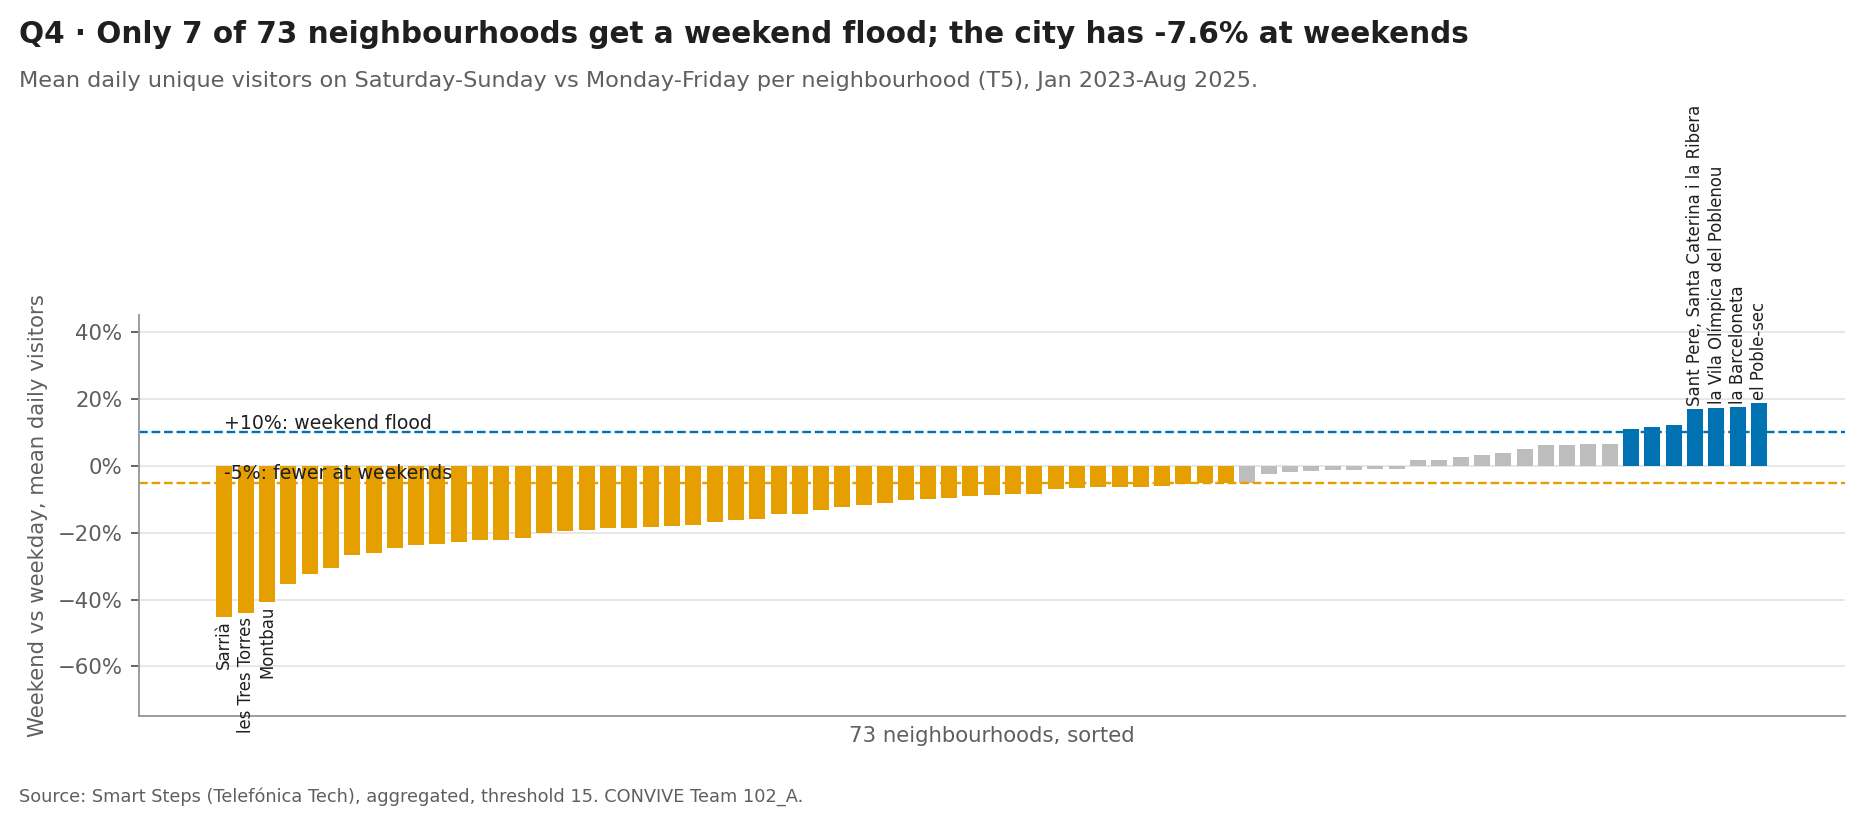

In [23]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q4_weekend_barrios.png"))

In [24]:
show("Q5")

#### Q5 · Did January-August visitors grow by more than 2% in both 2024 and 2025?

*Belief:* “Tourism keeps growing every year.”  
*Rule:* Visitors KEEP GROWING if the January-August mean grows by more than 2% in BOTH intervals (2023->2024 and 2024->2025). STABLE if both changes are within +/-2%. Otherwise MIXED. A neighbourhood is counted only with a base of at least 1,000 visitors per month.

All visitors: +5.1% (2023->2024) and +2.3% (2024->2025), January-August means. International tourists +14.7% and +3.7%; national visitors -4.9% and -2.6%. Neighbourhoods with a base of 1,000+: 25 keep growing, 1 stable, 5 keep falling, 42 mixed (of 73).

**Verdict: Keeps growing overall (+2% rule); keeps growing for international tourists; keeps falling for national visitors. Belief holds: Yes.**  
*Limitation:* Two intervals cannot prove a long-term trend; Feb 2024, Apr 2025 and May 2025 miss one day.

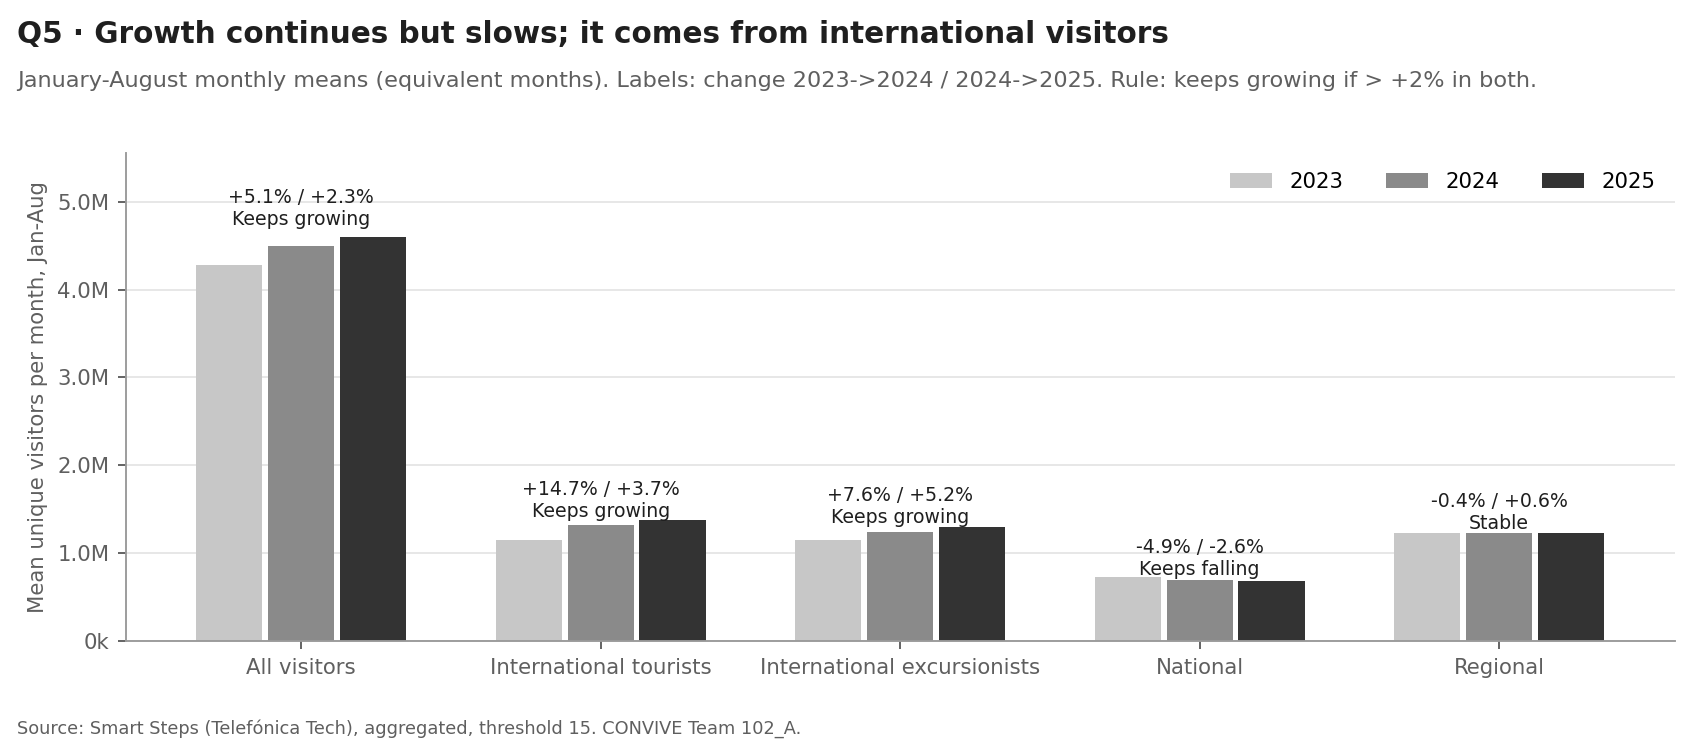

In [25]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q5_growth.png"))

In [26]:
show("Q7")

#### Q7 · Do at least half of the tourists of a week spend at most 2 nights?

*Belief:* “Tourists only stay for a weekend.”  
*Rule:* The 'weekend tourist' belief holds if at least 50% of the tourists of a week spend at most 2 nights (T3).

In 2024, international tourists: 72.6% spend 1-2 nights in a week, 13.9% 4 or more (mean 2.1 nights); national tourists: 63.1% spend 1-2 nights in a week, 26.4% 4 or more (mean 2.6 nights).

**Verdict: Holds: most tourists stay 1-2 nights per week. Belief holds: Yes.**  
*Limitation:* Municipality level; national and international tourists only; nights within one week.

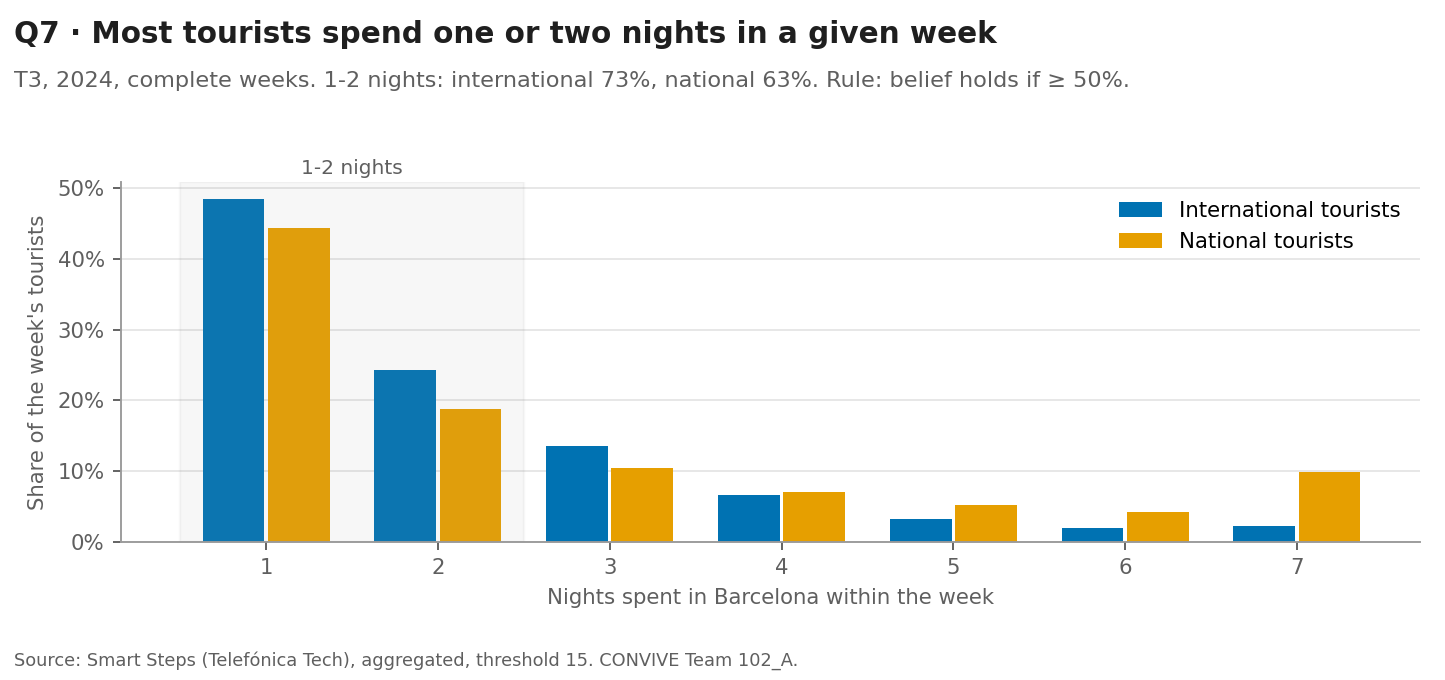

In [27]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q7_nights.png"))

In [28]:
show("Q9")

#### Q9 · Which days are at least 15% above (or below) the same weekday of the same month?

*Belief:* “Big events and holidays create visible peaks.”  
*Rule:* A day is an UNUSUAL PEAK if its unique visitors are at least 15% above the median of the same weekday in the same month (T2), and an UNUSUAL LOW if at least 15% below.

7 of 971 days are unusual peaks (>= +15% vs the same weekday and month) and 25 unusual lows. Largest peaks: 2025-04-28 (Mon, +39.4%), 2023-04-23 (Sun, +33.3%), 2023-09-18 (Mon, +17.6%), 2024-12-30 (Mon, +17.3%). The data date the peaks; naming their cause needs an external event calendar.

**Verdict: 7 peak days and 25 low days found. Belief holds: Partly.**  
*Limitation:* The data date the peaks but cannot name their cause.

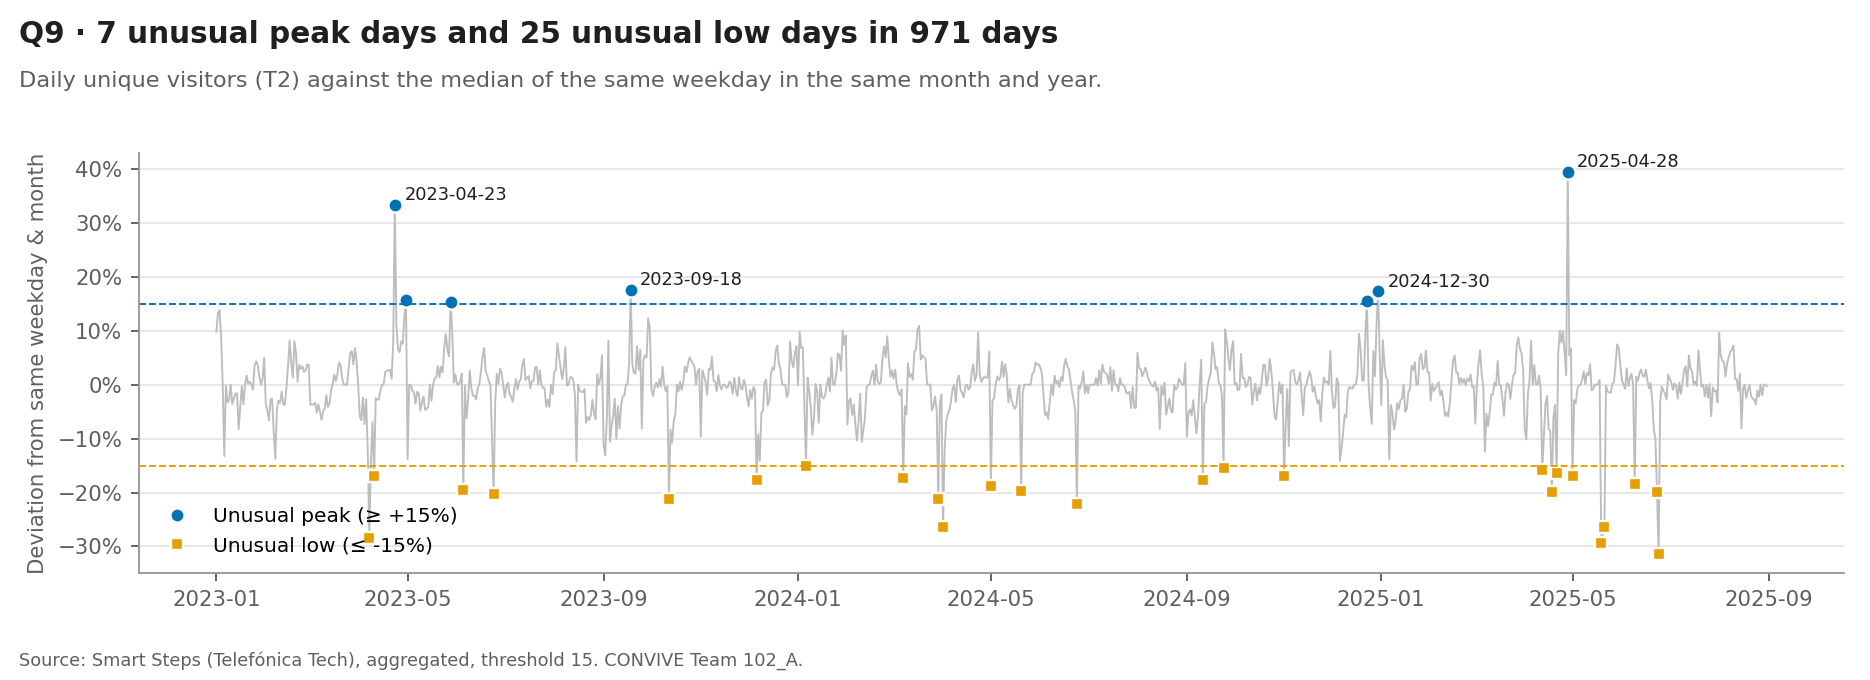

In [29]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q9_unusual_days.png"))

In [30]:
show("Q15")

#### Q15 · Do their weekday profiles differ by less than 5 points every day?

*Belief:* “Visitors and residents use the city at the same times.”  
*Rule:* Visitors and residents use the city at the SAME TIMES if their weekday profiles (trips per day as an index, mean day = 100) differ by less than 5 points on every weekday (M1).

Weekday index (mean day = 100), visitors vs residents: Saturday 95 vs 79, Sunday 79 vs 64; largest gap 16 points (Sat). By month, visitors' trips peak in Oct (116) while residents' trips are lowest in Aug (65).

**Verdict: Different rhythms. Belief holds: No.**  
*Limitation:* Trips only; no hourly data.

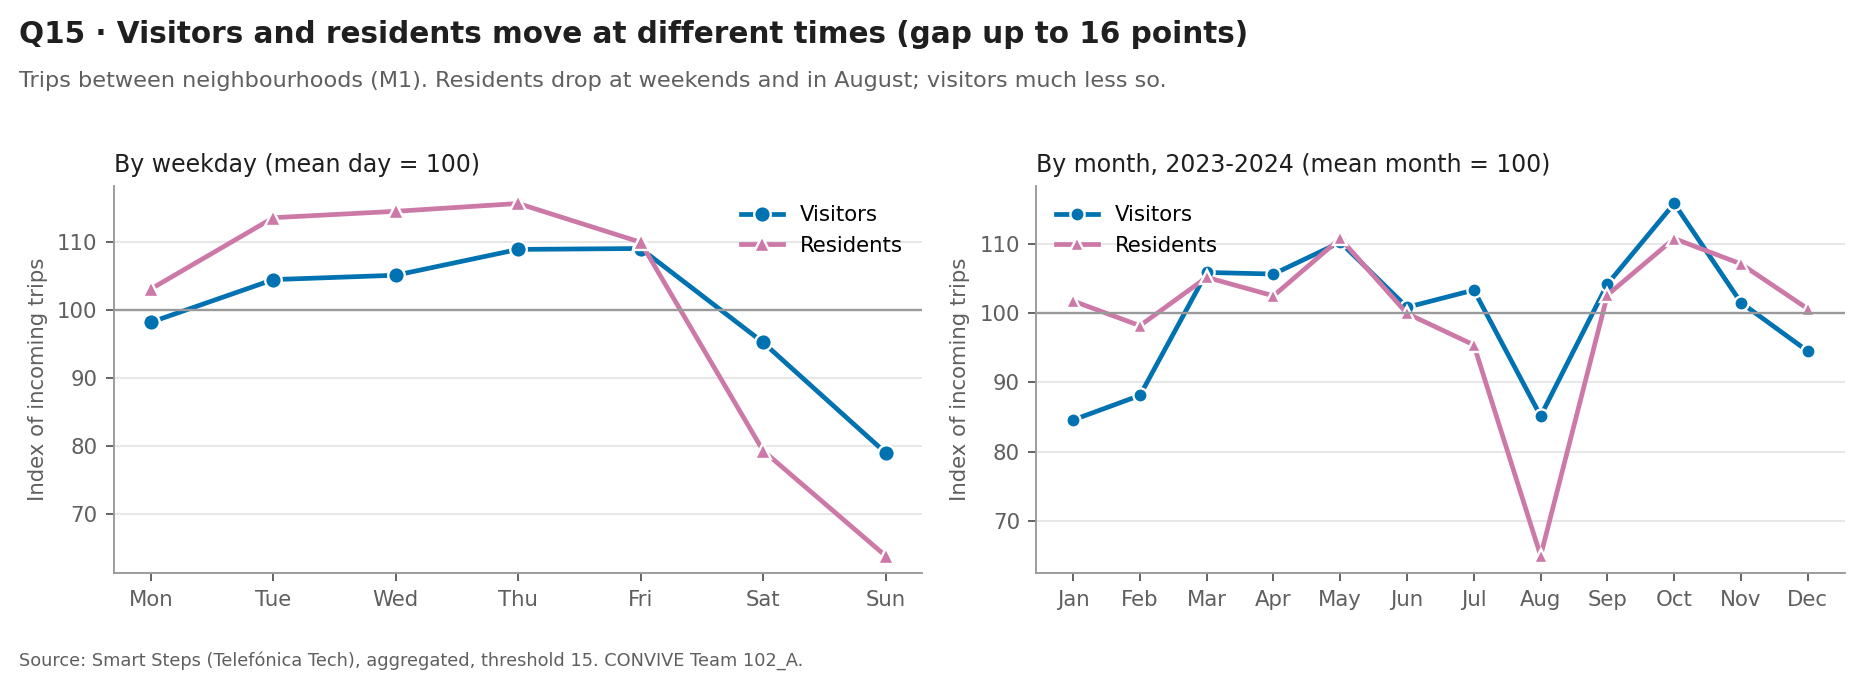

In [31]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q15_rhythm.png"))

### Who

In [32]:
show("Q3")

#### Q3 · In how many months are international visitors the majority, and from which countries?

*Belief:* “Most visitors are foreign tourists.”  
*Rule:* Visitors are MOSTLY FOREIGN if international visitors are more than 50% of monthly unique visitors (T1) in at least 75% of the months (24 of 32). Countries: a FEW COUNTRIES dominate if the top 5 countries hold at least 50% of international presences (T8).

International visitors are 55.2% of monthly unique visitors on average and above 50% in 22 of 32 months (range 43.1%-66.2%). Among overnight tourists they are 81.9%. By country of residence (T8) the top 5 are France 11.4%, United Kingdom 11.3%, United States 11.1%, Germany 9.7%, Italy 8.7%: together 52.1% of international presences; small countries grouped as NA are 0.4%.

**Verdict: Partly: international majority in 22 of 32 months, the rule needs 24; the top 5 countries hold half of international presences. Belief holds: Partly.**  
*Limitation:* Country shares are of presences; countries below 15 people per neighbourhood are grouped as NA.

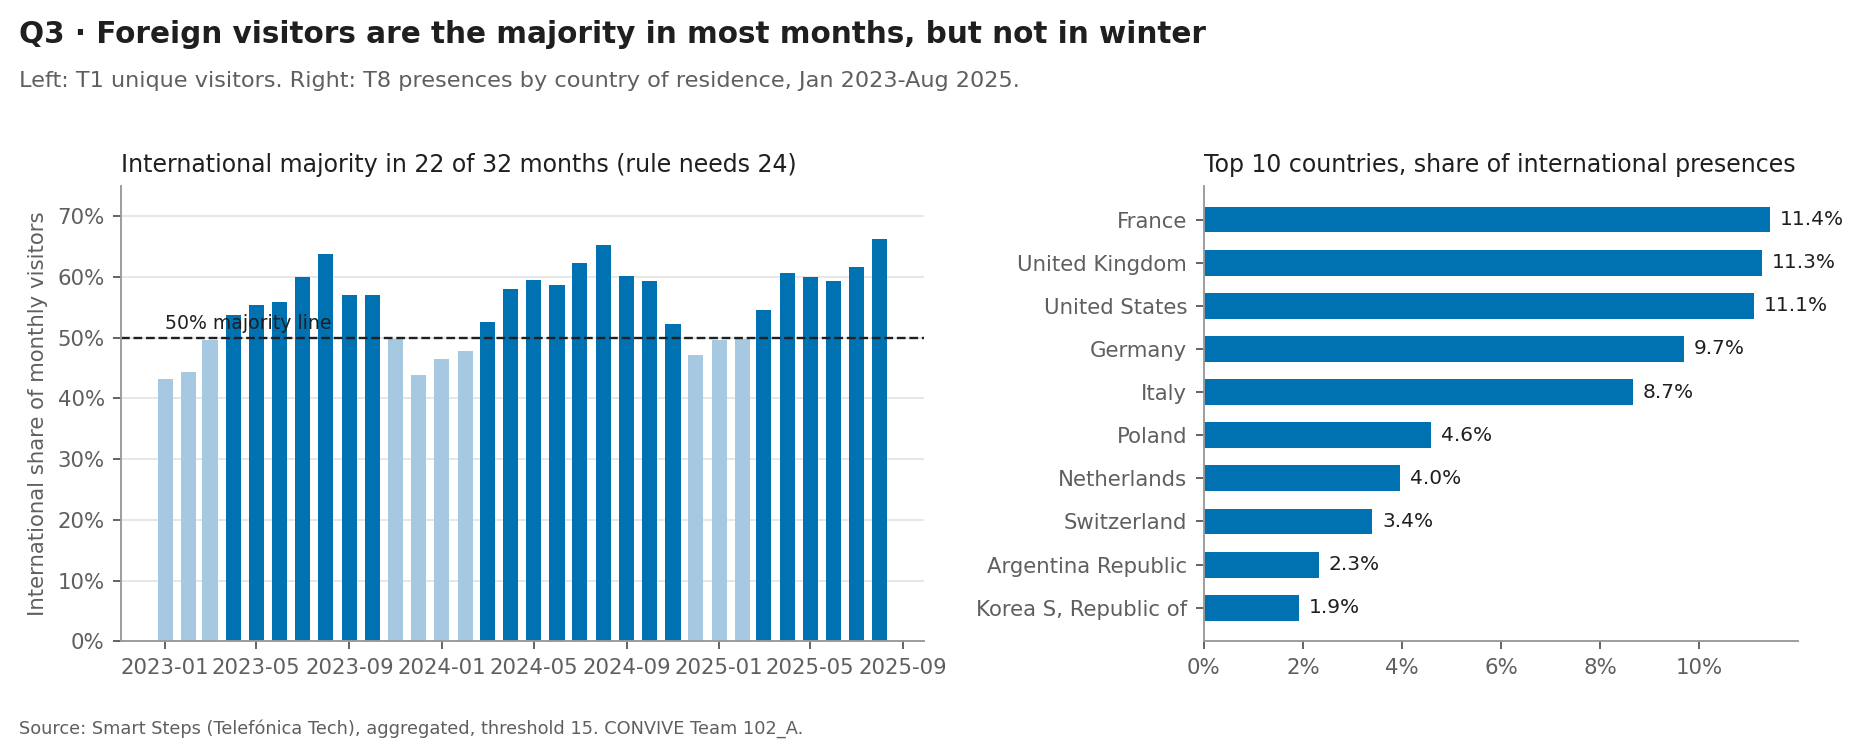

In [33]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q3_origin_countries.png"))

In [34]:
show("Q11")

#### Q11 · Do the top 5 countries hold at least half of international tourists?

*Belief:* “International visitors come from a few countries.”  
*Rule:* Same as Q3: a few countries dominate if the top 5 hold at least 50% of international presences.

Among international overnight tourists the top 5 countries hold 52.0% (United States 12.7%, United Kingdom 11.9%, France 9.8%, Germany 9.3%, Italy 8.4%). In 2024 the leading country is France in 43 of 73 neighbourhoods, United States in 13.

**Verdict: A few countries dominate. Belief holds: Yes.**  
*Limitation:* Small countries are grouped as NA in each neighbourhood.

In [35]:
show("Q12")

#### Q12 · Is Madrid at least half of national visitors?

*Belief:* “National visitors are mostly from Madrid.”  
*Rule:* National visitors are MOSTLY FROM MADRID if Madrid is at least 50% of national presences (T7). Madrid is the LARGEST single origin if it ranks first.

Top provinces of national visitors (presences): Girona 16.8%, Madrid 16.8%, Tarragona 14.9%, Lleida 6.8%, Balears, Illes 5.8%. Madrid is 16.8%; the other three Catalan provinces together 38.5%.

**Verdict: Not mostly from Madrid (16.8%); Girona and Madrid are level as the largest. Belief holds: No.**  
*Limitation:* 'National' excludes the province of Barcelona (those are regional).

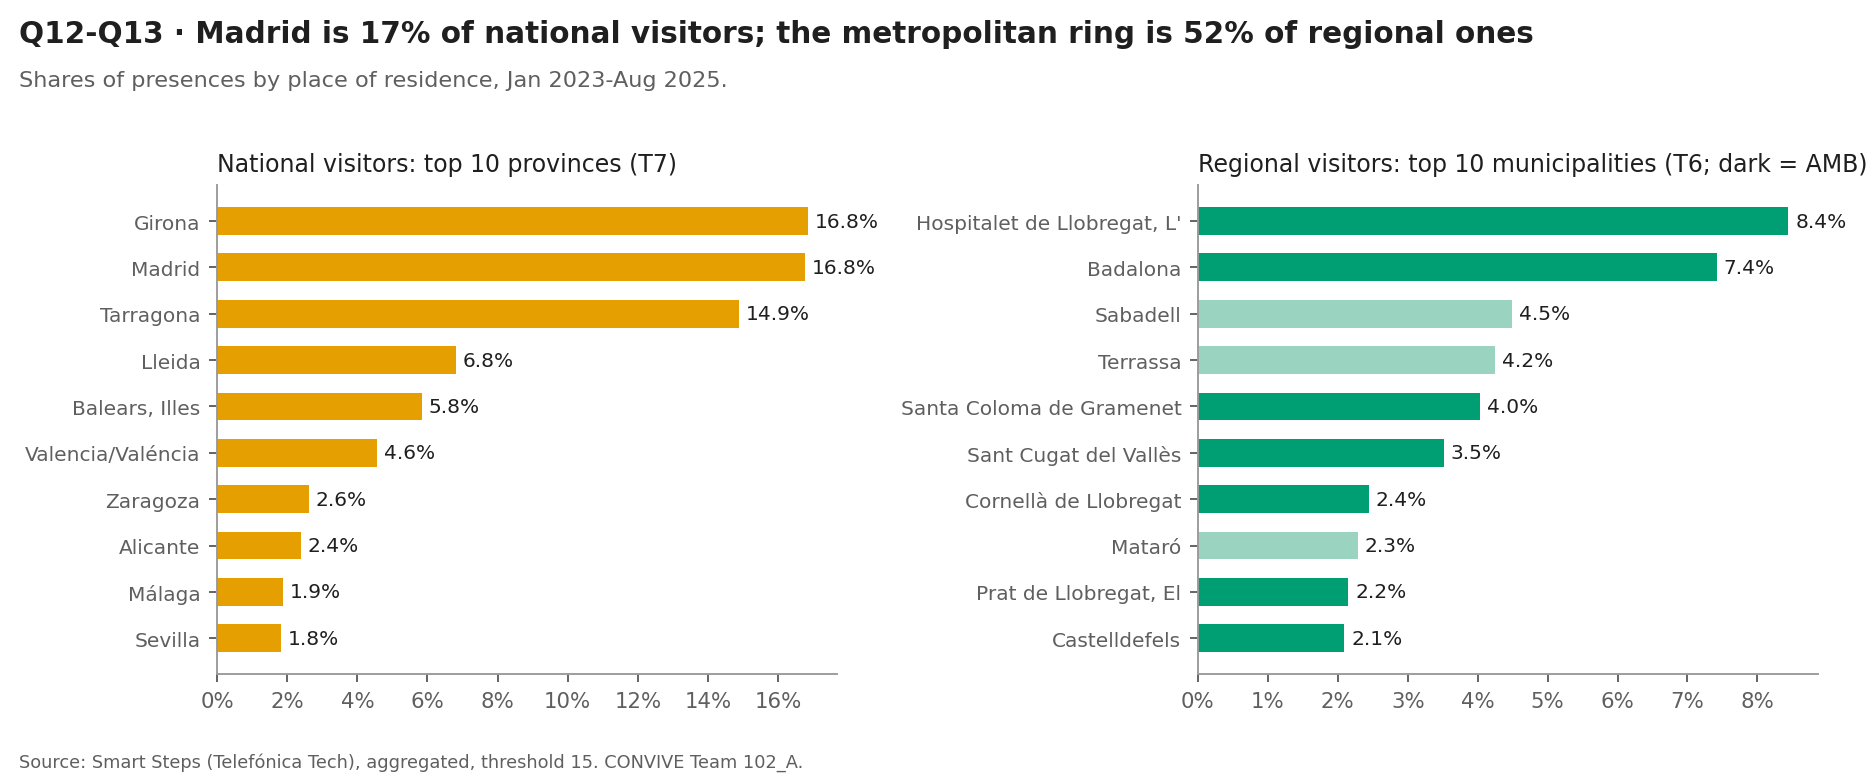

In [36]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q12_q13_residence.png"))

In [37]:
show("Q13")

#### Q13 · Do the other 35 AMB municipalities send at least half of regional visitors?

*Belief:* “Regional visitors come from the metropolitan ring.”  
*Rule:* Regional visitors come MOSTLY FROM THE METROPOLITAN RING if the 35 other municipalities of the Àrea Metropolitana de Barcelona hold at least 50% of regional presences (T6).

The 35 other AMB municipalities hold 52.5% of regional presences (35 of 35 found by name). Top: Hospitalet de Llobregat, L' 8.4%, Badalona 7.4%, Sabadell 4.5%, Terrassa 4.2%, Santa Coloma de Gramenet 4.0%.

**Verdict: Mostly from the metropolitan ring. Belief holds: Yes.**  
*Limitation:* M3 (trips) is not used because of the repeated keys (I7).

In [38]:
show("Q14")

#### Q14 · Are at least half aged 18-39, and at least half high or medium-high income?

*Belief:* “Visitors are young and high-income.”  
*Rule:* Visitors are YOUNG if the 18-39 age groups hold at least 50% of presences, and HIGH-INCOME if the 'Alto' and 'Medio-Alto' income levels hold at least 50% (T9, national and regional only).

National and regional visitors (T9 has no international rows, issue I9): 18-39 years 36.0%, 60+ 27.5%; high or medium-high income 76.4%, low income 4.2%; women 49.2%.

**Verdict: Not young (36% aged 18-39), but high-income (76% high or medium-high); national and regional only. Belief holds: Partly.**  
*Limitation:* T9 has no international visitors (I9): national and regional only.

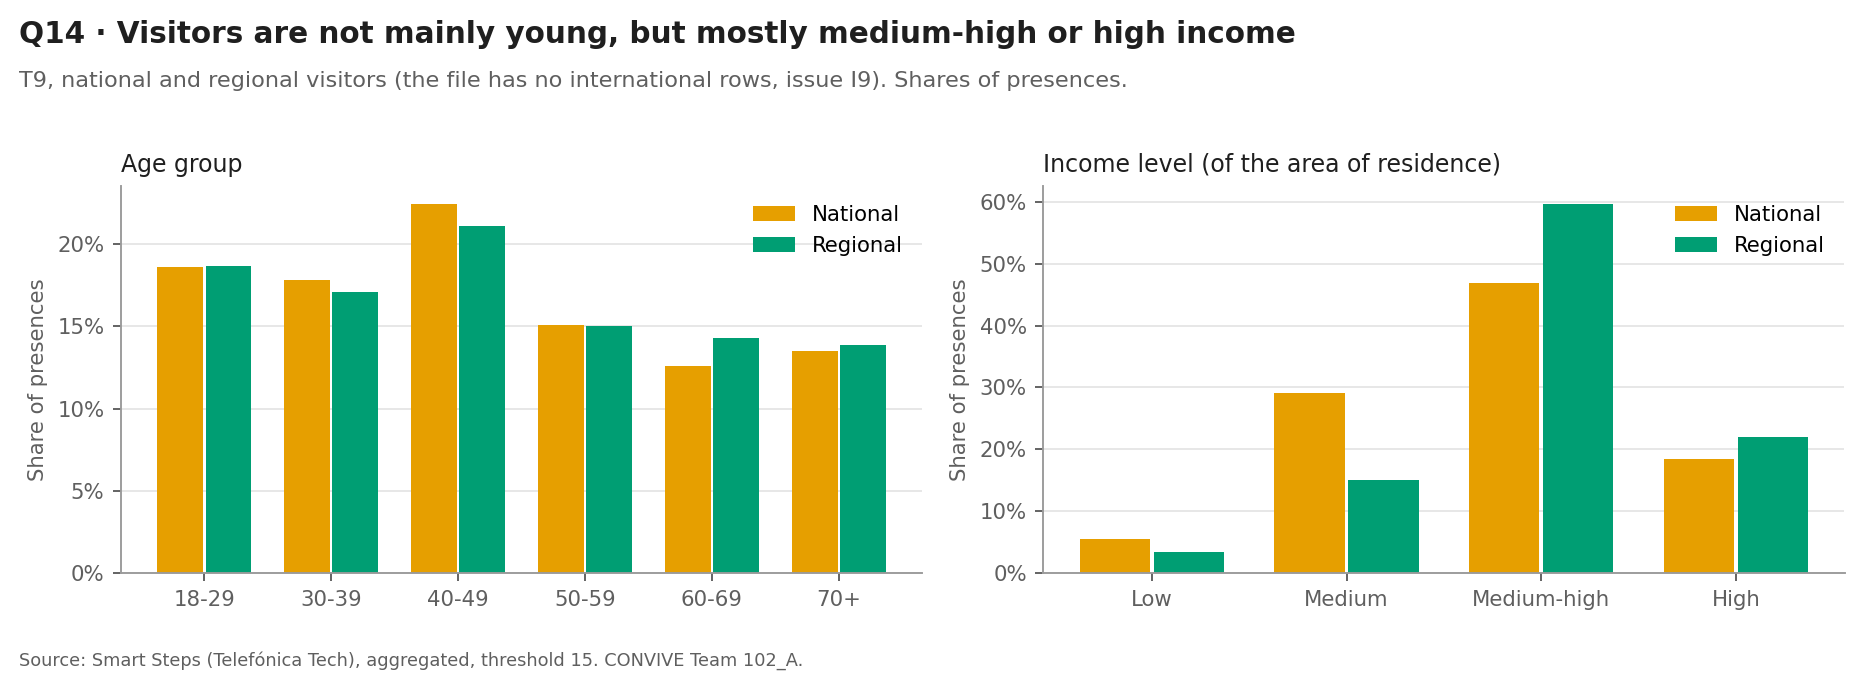

In [39]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q14_profile.png"))

In [40]:
show("Q17")

#### Q17 · Which country markets grew more than 20% (January-August 2023->2025)?

*Belief:* “The tourist mix is always the same countries.”  
*Rule:* A country market is GROWING FAST if its January-August presences grew by more than 20% between 2023 and 2025. Only countries with at least 1% of international presences in 2023 are ranked.

9 of 18 country markets with at least 1% of presences grew by more than 20% (January-August, 2023 to 2025): Poland +119.0%, Argentina Republic +110.7%, Canada +59.2%, Turkey +50.6%, Korea S, Republic of +49.4%, United States +35.5%. Lowest: United Kingdom -13.4%, Germany -16.6%, Mexico -51.2%.

**Verdict: 9 fast-growing markets. Belief holds: No.**  
*Limitation:* Presences, not people; equivalent months only.

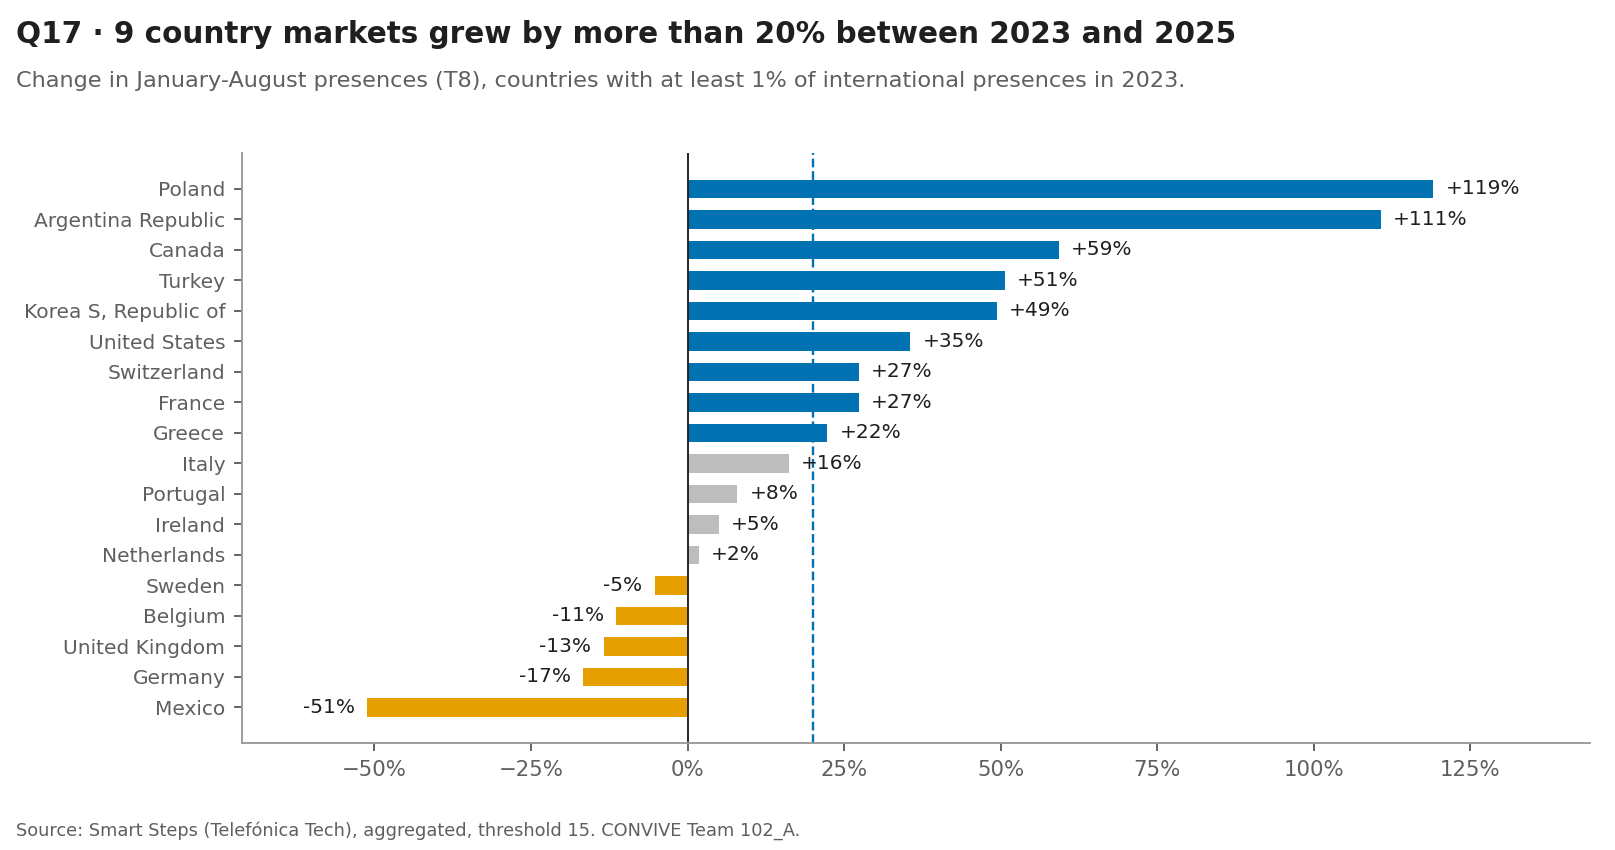

In [41]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/q17_country_growth.png"))

In [42]:
show("Q18")

#### Q18 · Are at least 16 of the 20 main country markets summer markets (June-August >= 1.30x the other months)?

*Belief:* “Foreign tourists all come in summer.”  
*Rule:* A country market is a SUMMER MARKET if its June-August monthly mean is at least 1.30 times the mean of the other nine months (the Q2 threshold, full years 2023 and 2024). The belief holds if at least 16 of the 20 main markets (80%) are summer markets; PARTLY if 10 to 15; NO if fewer than 10.

6 of the 20 main markets are summer markets (June-August >= 1.30x the other months): Germany 1.45x, United Kingdom 1.44x, France 1.40x, United States 1.39x, Mexico 1.39x, Netherlands 1.39x. The least seasonal markets peak outside summer: Japan 0.65x (peak Oct), Greece 0.79x (peak Mar), Korea S, Republic of 0.79x (peak Dec), Portugal 1.05x (peak Apr), China 1.06x (peak Oct). The 20 markets hold 82.7% of international presences.

**Verdict: Only 6 of 20 markets are summer markets. Belief holds: No.**  
*Limitation:* Presences, not people; small countries grouped as NA are left out.

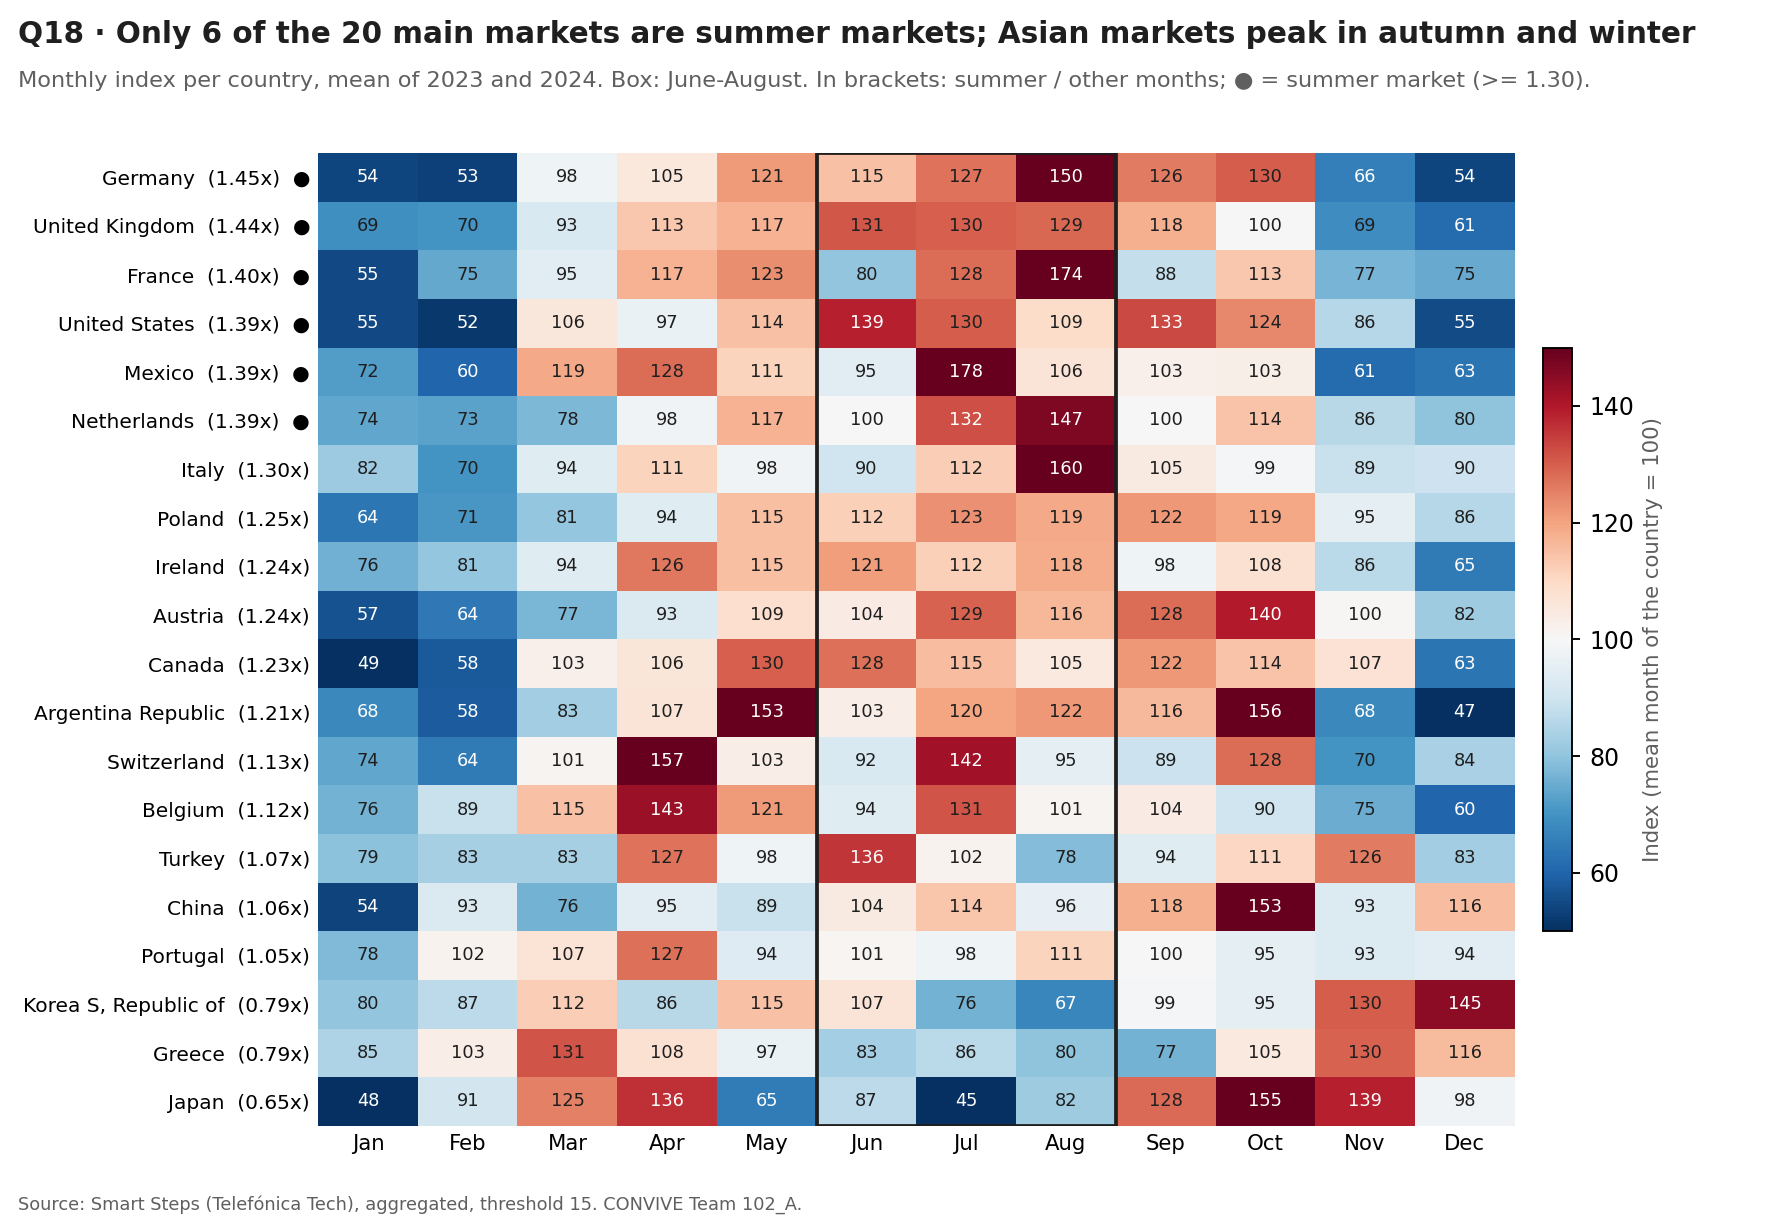

In [43]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/nat_season_heatmap.png"))

In [44]:
show("Q19")

#### Q19 · Do the 20 main markets share at least 7 of their top-10 neighbourhoods, and do they have niches of their own?

*Belief:* “Every nationality goes to the same neighbourhoods.”  
*Rule:* A country market FOLLOWS the international pattern if at least 7 of its top-10 neighbourhoods are in the top 10 of all international visitors (the Q10 threshold). It has its OWN NICHE if a neighbourhood with at least 1,000 presences per month of that market has a location quotient >= 1.25. The belief holds if at least 16 of the 20 main markets follow the pattern and fewer than half have a niche; PARTLY if they follow it but at least half have a niche; NO if fewer than 16 follow it.

20 of the 20 main markets share at least 7 of their top-10 neighbourhoods with all international visitors (la Dreta de l'Eixample is first for 19 of them). 17 of 20 also have their own niche (LQ >= 1.25 with >= 1,000 presences per month): France in Torre Baró (2.99), Korea S, Republic of in el Carmel (2.80), China in Vallvidrera, el Tibidabo i les Planes (2.71), Netherlands in Sarrià (2.11), Japan in el Baix Guinardó (1.90), Argentina Republic in el Camp de l'Arpa del Clot (1.86).

**Verdict: Same main neighbourhoods for every market, plus a niche of their own for most. Belief holds: Partly.**  
*Limitation:* Neighbourhood x country values exist by year only (no visitor type); LQ uses presences.

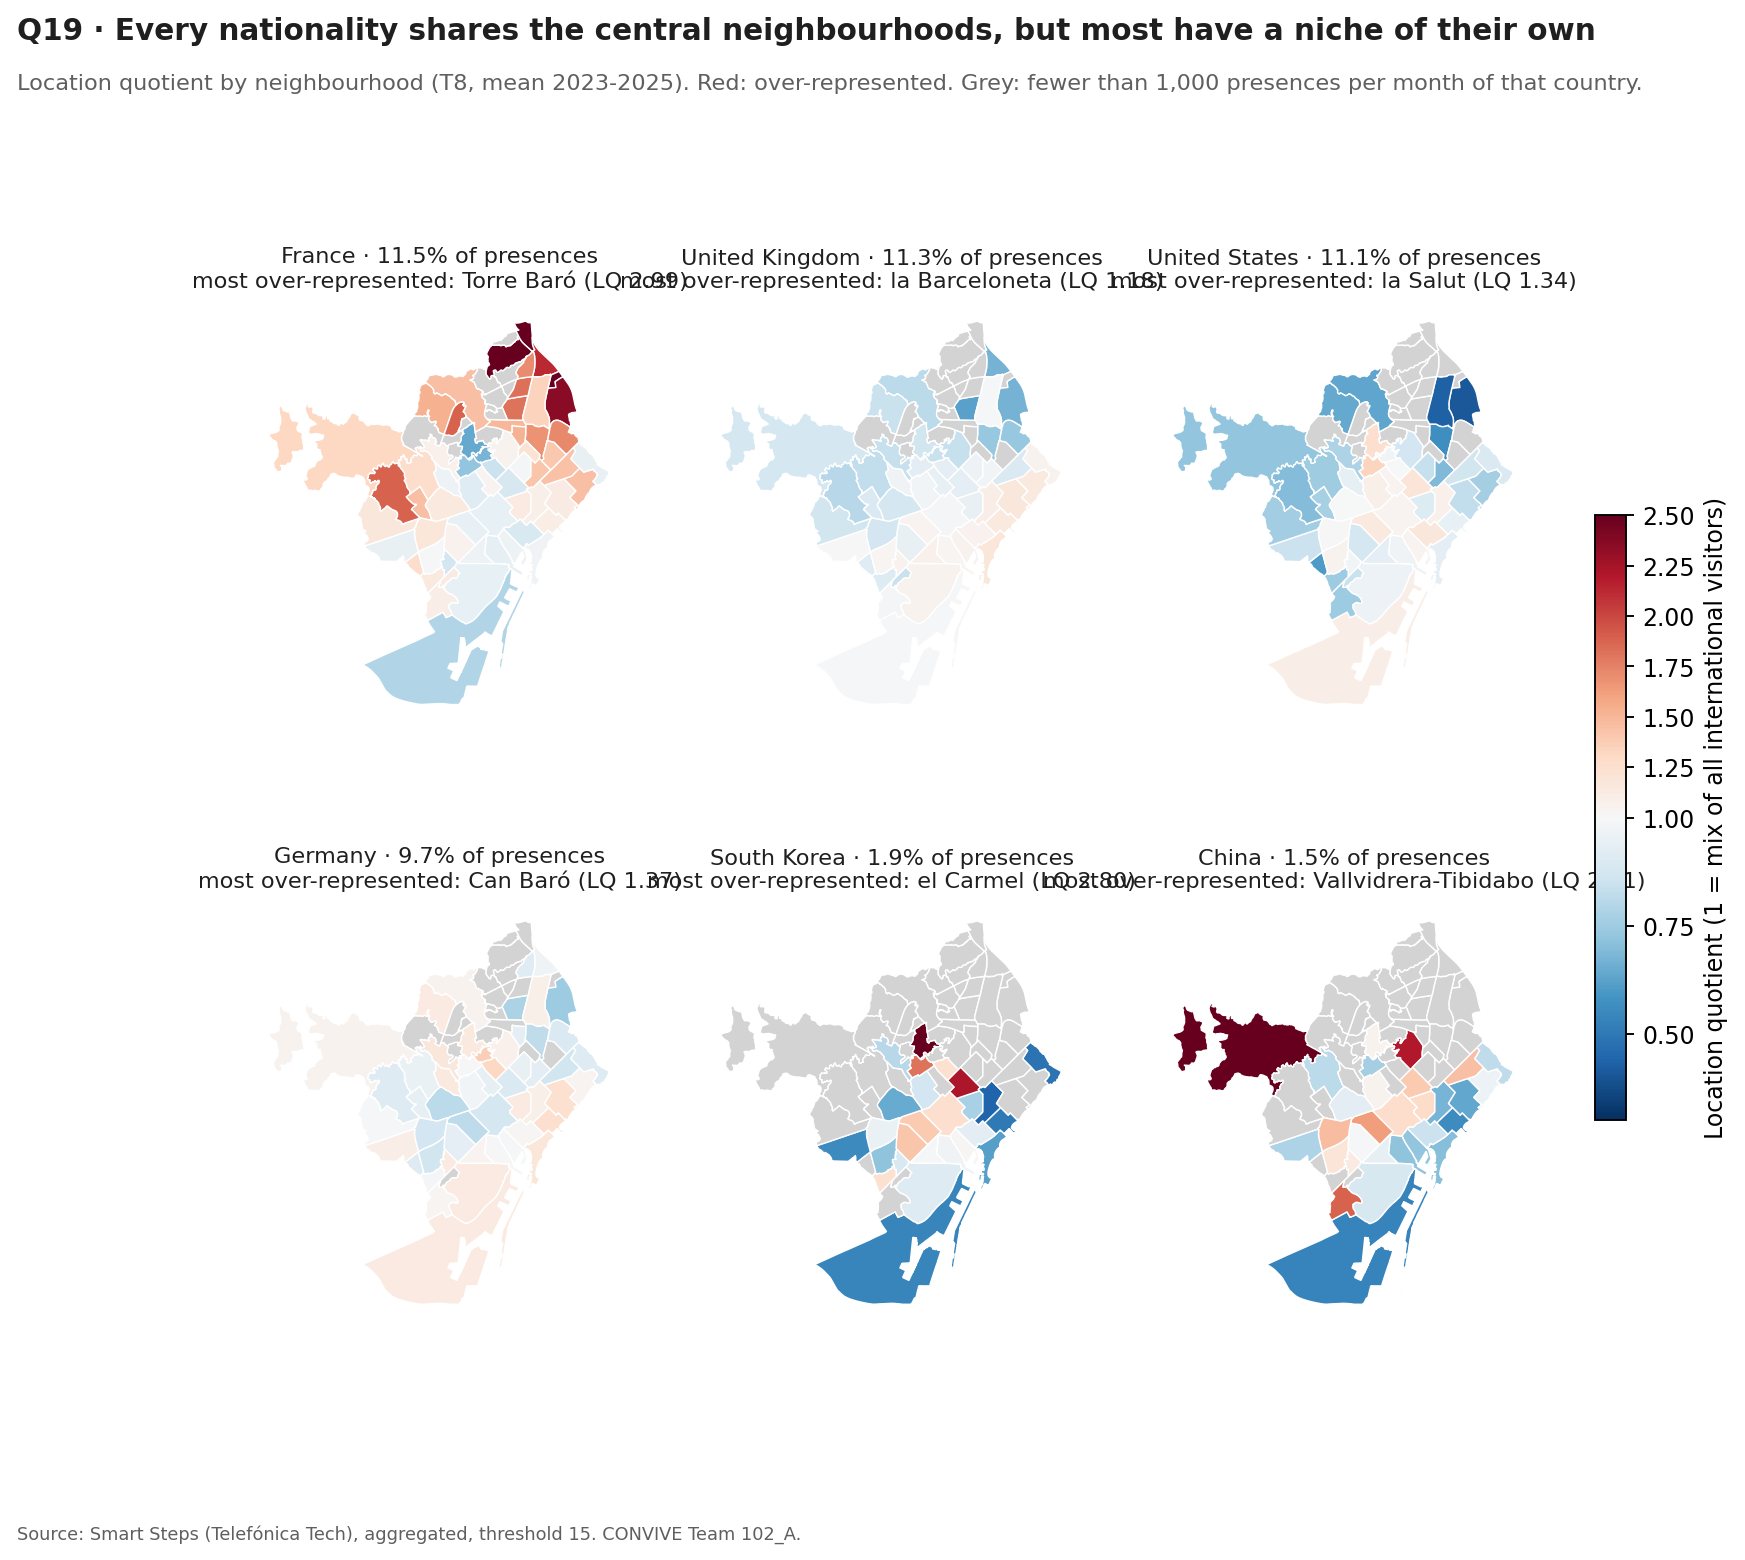

In [45]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/nat_lq_maps.png"))

In [46]:
show("Q20")

#### Q20 · Are overnight tourists at least half of the presences in at least 16 of the 20 main markets?

*Belief:* “International visitors are overnight tourists.”  
*Rule:* A country market is MOSTLY OVERNIGHT if overnight tourists ('Turista') are at least 50% of its presences (T8). The belief holds if at least 16 of the 20 main markets are mostly overnight; PARTLY if 10 to 15; NO if fewer than 10.

20 of the 20 main markets are mostly overnight tourists. Highest share of overnight tourists: Greece 84.4%, Japan 81.8%, United States 81.2%; lowest: Korea S, Republic of 60.4%, France 60.9%, Netherlands 63.3%, Portugal 67.3%. None of the top 50 countries is mostly day-trippers.

**Verdict: Mostly overnight tourists in every main market. Belief holds: Yes.**  
*Limitation:* Presences, not people; a person who is a tourist one month and an excursionist another counts in both.

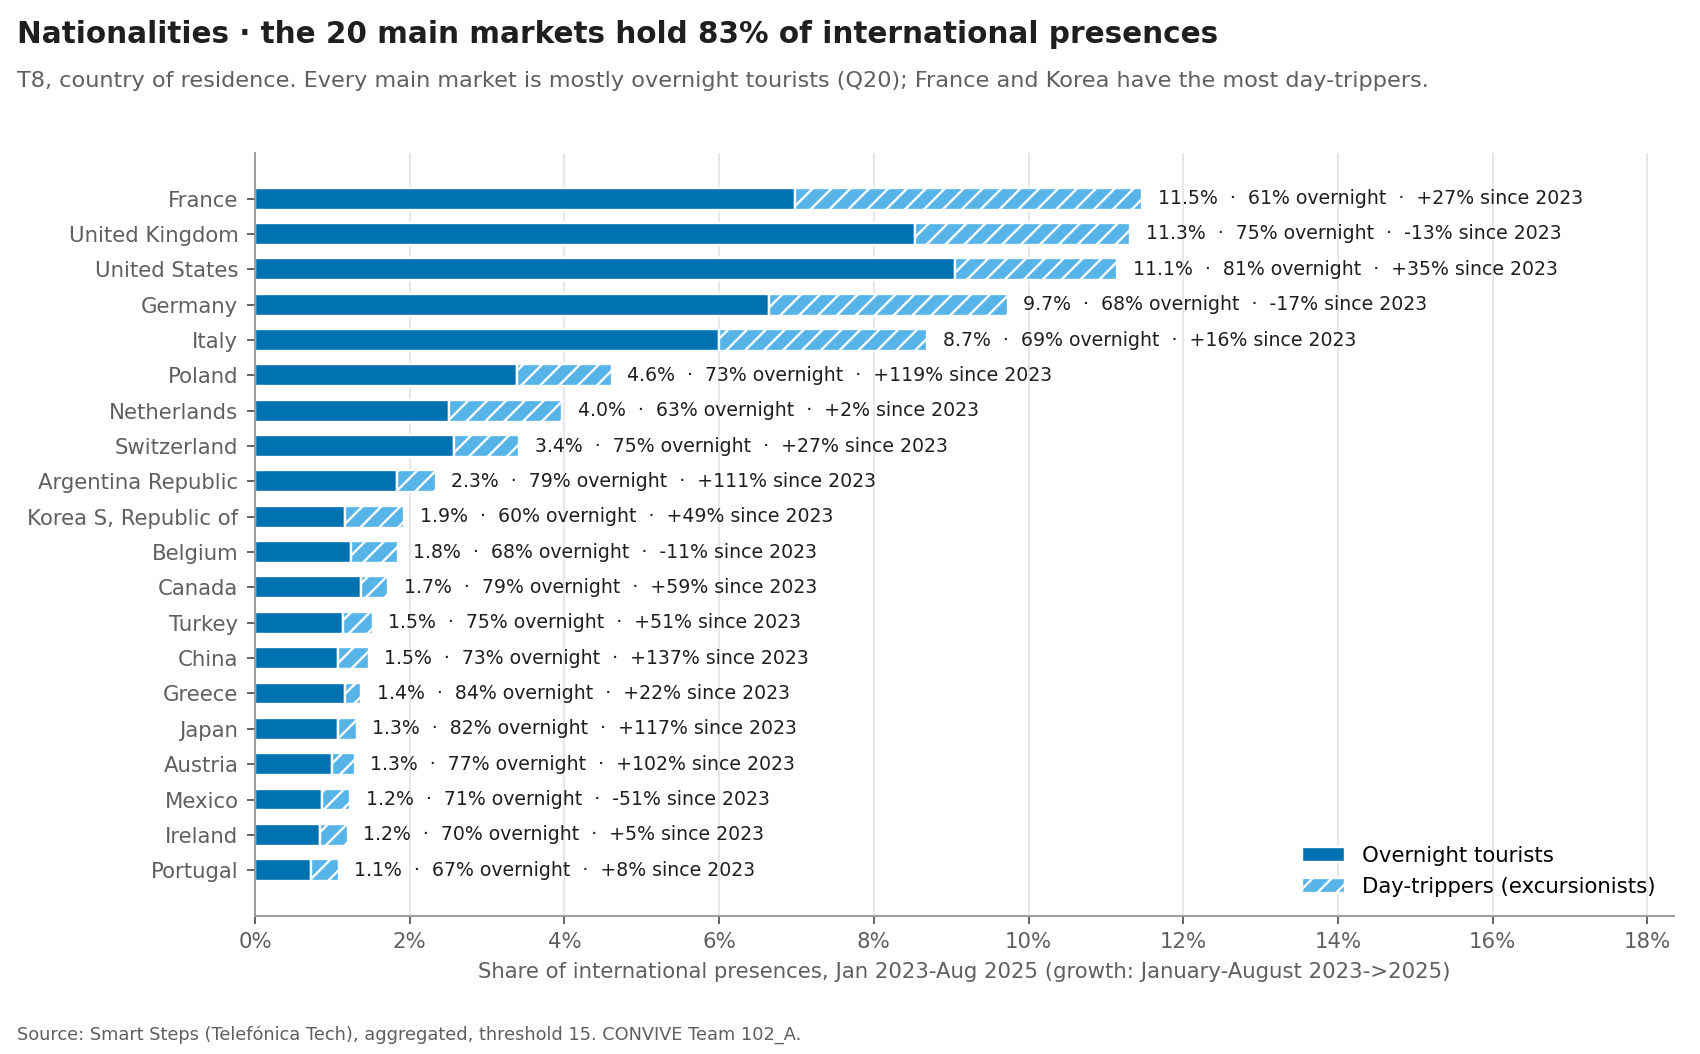

In [47]:
Image(filename=str(R.HERE / "deliverables" / "iteration3/figures/nat_markets.png"))

## 5. Robustness and limits

Each question is recomputed with its main threshold 10% and 20% lower and higher. A verdict is near its threshold if it changes already at 10%.

In [48]:
robust = S.run(t, r)
robust

,id,threshold,value,base,-20%,-10%,+10%,+20%,robustness
0,Q0,change in the visitor share (points),0.02,Yes,Yes,Yes,Partly,Partly,Near threshold
1,Q0,neighbourhoods needed,37.00,Yes,Yes,Yes,Partly,Partly,Near threshold
2,Q1,N50 in neighbourhoods,11.00,Yes,No,Yes,Yes,Yes,Moderate
3,Q2,summer / other months,1.30,No,No,No,No,No,Robust
4,Q3,share of months with an international majority,0.75,Partly,Yes,Yes,Partly,Partly,Near threshold
5,Q4,weekend change,0.10,No,No,No,No,No,Robust
6,Q5,yearly growth,0.02,Yes,Yes,Yes,Yes,No,Moderate
7,Q6,visitor share of incoming trips,0.50,Partly,Yes,Yes,Partly,Partly,Near threshold
8,Q7,share of tourists with 1-2 nights,0.50,Yes,Yes,Yes,Yes,Yes,Robust
9,Q8,top-10 neighbourhoods kept,8.00,Yes,Yes,Yes,Yes,No,Moderate


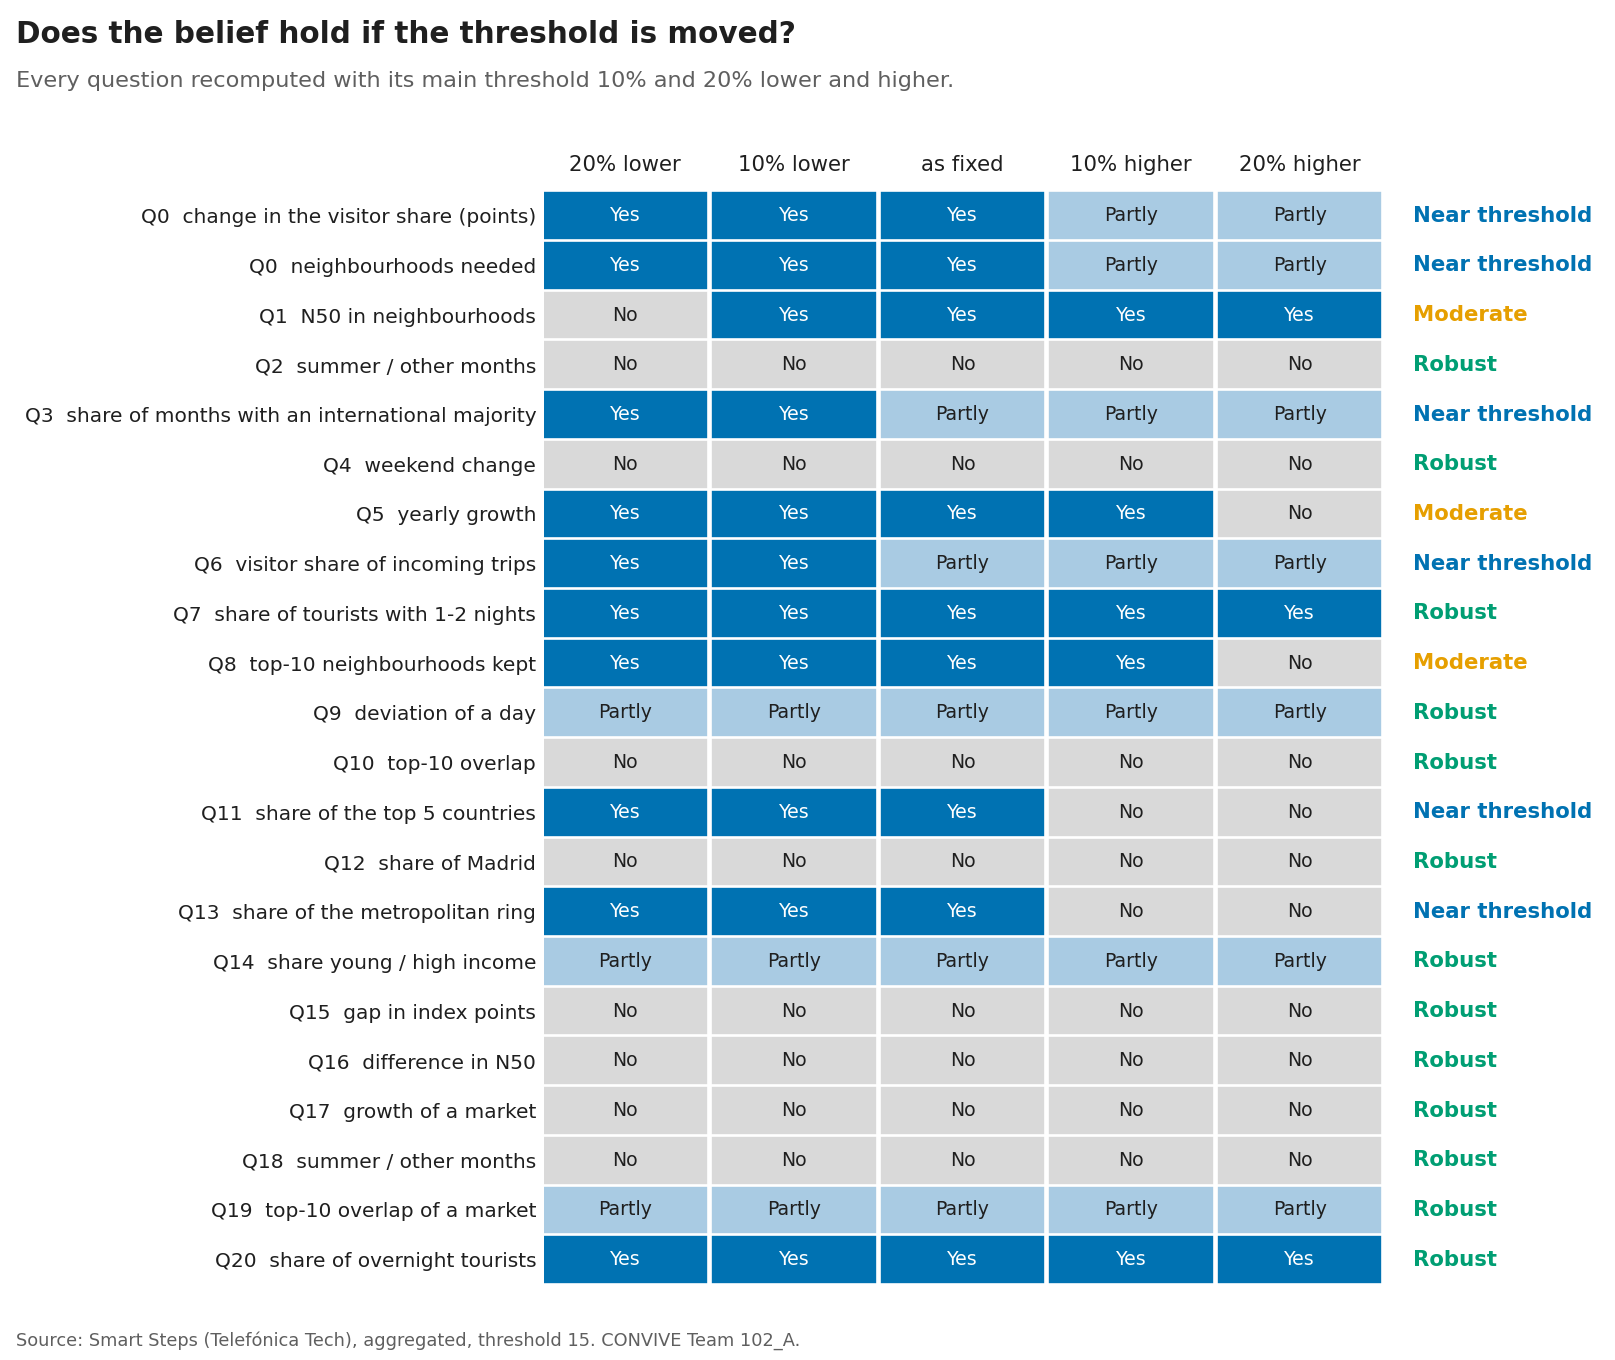

In [49]:
Image(filename=str(R.HERE / "deliverables" / "final/figures/verdict_robustness.png"))

The scan below looks for level shifts in the 73 neighbourhood series (issue I8).

In [50]:
shifts = B.run(t)
shifts["found"][["barrio_name", "distrito_name", "product", "month", "ratio"]].round(2)

,barrio_name,distrito_name,product,month,ratio
0,Can Peguera,Nou Barris,M1 visitor trips,202404,0.14
1,Can Peguera,Nou Barris,T4 visitors,202404,0.19
2,Verdun,Nou Barris,T4 visitors,202308,0.28
3,Vallbona,Nou Barris,T4 visitors,202311,0.33
4,Verdun,Nou Barris,M1 visitor trips,202309,2.58
5,el Turó de la Peira,Nou Barris,M1 visitor trips,202404,2.31
6,Canyelles,Nou Barris,T4 visitors,202403,0.45
7,Vallbona,Nou Barris,M1 visitor trips,202407,0.47
8,Baró de Viver,Sant Andreu,M1 visitor trips,202308,2.04
9,la Teixonera,Horta-Guinardó,M1 visitor trips,202311,2.02


In [51]:
shifts["pair"].round(2)

,product,area,before,after,change
0,T4 visitors per month,Can Peguera,31073.17,7243.67,-0.77
1,T4 visitors per month,el Turó de la Peira,18011.33,33167.83,0.84
2,T4 visitors per month,both,49084.50,40411.50,-0.18
3,M1 visitors' trips per day,Can Peguera,573.35,89.23,-0.84
4,M1 visitors' trips per day,el Turó de la Peira,479.90,1126.29,1.35
5,M1 visitors' trips per day,both,1053.25,1215.52,0.15
6,M1 residents' trips per day,Can Peguera,1606.78,488.55,-0.70
7,M1 residents' trips per day,el Turó de la Peira,2850.76,5648.75,0.98
8,M1 residents' trips per day,both,4457.54,6137.29,0.38


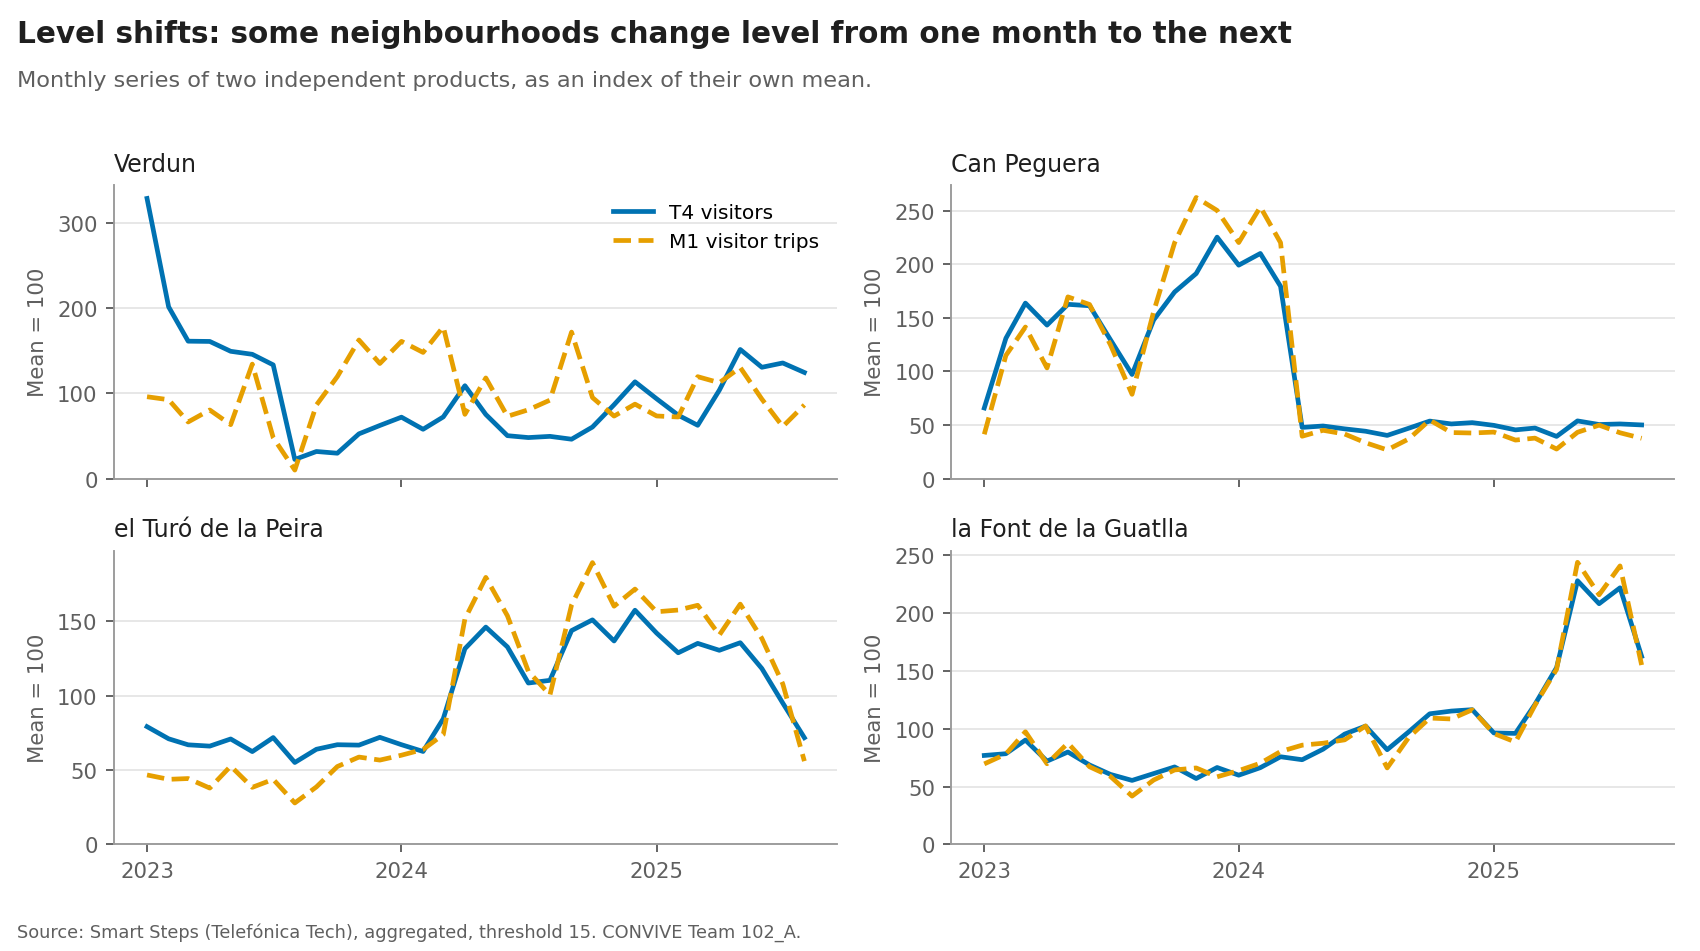

In [52]:
Image(filename=str(R.HERE / "deliverables" / "final/figures/level_shifts.png"))

In [53]:
low = r["low_data"]
low[low["low_data"]][["barrio_name", "distrito_name", "mean_monthly_visitors", "vs_median", "resident_trips_vs_median", "visitor_share_trips", "reason"]].round(3)

,barrio_name,distrito_name,mean_monthly_visitors,vs_median,resident_trips_vs_median,visitor_share_trips,reason
0,Verdun,Nou Barris,985.719,0.007,0.426,0.009,very low visitors + many grouped segments
1,la Teixonera,Horta-Guinardó,2760.656,0.021,0.588,0.025,very low visitors + many grouped segments
2,Ciutat Meridiana,Nou Barris,5209.000,0.039,0.259,0.080,very low visitors + many grouped segments
3,les Roquetes,Nou Barris,6567.344,0.049,0.289,0.027,very low visitors
4,el Coll,Gràcia,8673.250,0.065,0.236,0.061,very low visitors
5,Canyelles,Nou Barris,10013.969,0.074,0.126,0.063,very low visitors


**Data questions and how they are managed.** I7: repeated keys in M3 (not used here). I8: low-data neighbourhoods and level shifts. I9: no international visitors in T9.

**Dashboard.** `python -m streamlit run app/dashboard.py` reads the tables written by this notebook.